<a id="summary"></a>

# Tổng kết: mọi kết quả OPERA trong workspace (cập nhật 18/11/2026)

> **Nguồn (tất cả trong `results/`, mục lục ở `results/README.md`):** `runs/` (778 run, mỗi run một bản), `sweep/` (564 file severity sweep), `bao_cao/2026-11-18/per_run.csv` và `bao_cao/2026-11-15/per_run.csv` (bảng MSE của hai gói), run VitalDB của iTransformer / PatchTST / TMix trong `runs/` (trước nằm ở `plugin_vitaldb`), và `cu_ce9a1cc/per_seed_results.csv` (kết quả cũ: forecasting setting cũ, classification, native shift, OPERA++). Notebook ghi bản gộp ra `results/tong_hop/per_run_merged.csv` và `results/tong_hop/sweep_long.csv`. *File này đã gộp nội dung của file severity sweep cũ (thắng/thua theo mức, đường cong theo dataset, chỗ thua, trong/ngoài vùng train, chỗ lạ của Warpformer) và mở rộng cho mọi backbone có sweep. Phân tích chi tiết native backbone: [02](02_native_backbone_analysis.ipynb).*
>
> **Kiểm tra khi gộp:** 510 run có ở cả hai gói cho MSE giống hệt (sai khác 0). Sweep khớp `per_run` ở 2820 điểm protocol (sai khác ≤ 2.3e-5, dưới ngưỡng 1e-4 của `reevaluate.py`).
>
> **Trả lời ngắn:** Forecasting, 11 backbone × 8 dataset: khi shift, OPERA thắng **755/800** cặp ở native và **674/688** ở non-native. Khi clean, native **gần hòa** (125/200 cặp, trung vị theo backbone −2.2% đến +1.6%), non-native **kém đi** (19/172 cặp, −3.2% đến −6.3%). Đường cong theo mức nặng giờ có **đủ 11 backbone**: ở mức nặng nhất, OPERA tụt ít hơn Vanilla ở **44/44** ô backbone × loại shift. Với non-native, Vanilla sụp rất mạnh (density 0.7: −824% so với Vanilla lúc sạch) còn OPERA chỉ −97%. Kết quả cũ trong `results/` cùng chiều: classification thắng cả clean lẫn shift ở hầu hết ô; chỗ yếu là USHCN 12 tháng (irregular) và native shift với PatchTST.

#### Có gì trong 2 tuần

| Ngày | Việc | Nguồn |
|---|---|---|
| 10–11/11 | GRU-D, mTAND, Warpformer · 8 dataset (commit `e606587`) | `bao_cao/2026-11-12_native/` |
| 12/11 | Severity sweep 20 điều kiện cho 3 native đầu | `sweep/`, `bao_cao/2026-11-12_native/severity/` |
| 13–15/11 | Backbone mới: t-PatchGNN, GraFITi, CRU, DLinear, SegRNN; sửa lỗi t-PatchGNN pooling, CRU khởi tạo | `bao_cao/2026-11-15/TONG_KET.md`, `bao_cao/2026-11-15/code/` |
| 15–18/11 | **Sweep cho mọi run có checkpoint**: 6 native, DLinear, SegRNN (8 dataset, 3–5 seed), iTransformer / PatchTST / TMix (chỉ CGMacros) | `sweep/`, `bao_cao/2026-11-18/` |
| trước đó | iTransformer / PatchTST / TMix trên NOAA, CGMacros, VitalDB (commit `062d811`) và các setting cũ (commit `ce9a1cc`) | `bao_cao/plugin_*`, `cu_ce9a1cc/` |

#### Kết luận theo từng phần

| Phần | # | Kết luận | Bằng chứng | Xem hình |
|---|---|---|---|---|
| §1 | 1 | Shift: OPERA thắng ở **mọi backbone**, mọi dataset | Native 755/800 cặp, non-native 674/688. Trung vị theo backbone: native +18.6% đến +31.0%, non-native +57.6% đến +78.2%. Ô yếu nhất: USHCN · CRU +0.2%, USHCN · Warpformer +1.1% | [Hình 1.1b](#hinh-1-1), [Bảng 1.2](#bang-1-2) |
| §1 | 2 | Clean: **native gần hòa, non-native kém đi** | Native 125/200 cặp; 5/6 backbone có trung vị −0.0% đến +1.6%, riêng CRU −2.2% (2 dataset). Non-native 19/172 cặp; mọi backbone thắng ≤ 1 dataset | [Hình 1.1a](#hinh-1-1), [Bảng 1.2](#bang-1-2) |
| §1 | 2b | **Bảng kết quả kiểu file 00** (MSE; Vanilla, OPERA mean ± std, % cải thiện, seed / ô thắng) | Clean: TB native +0.76% (29/40 ô), non-native −6.62% (2/36 ô). Shifted (MSE trung bình 4 shift): native +31.8%, non-native +60.4%, OPERA thắng **76/76 ô** | [Bảng 1.2b](#bang-1-2b) |
| §1 | 3 | Chi phí clean **đi theo nhóm backbone**: ở cùng mức nhạy, non-native vẫn mất còn native thì không | Vùng nhạy chung ×1.06–11.5: native +0.6% (38 ô), non-native −3.6% (23 ô). Spearman (Vanilla tụt, clean): native +0.02 (p = 0.92), non-native −0.55 (p = 5e-4) | [Hình 1.3](#hinh-1-3), [Bảng 1.4](#bang-1-4) |
| §1 | 4 | Trong non-native, chi phí lớn nhất ở **NOAA**, nơi Vanilla sụp mạnh nhất và vốn yếu hơn native | NOAA: trung vị −22%, tệ nhất SegRNN −52% (3 seed, Vanilla tụt ×170 khi shift); MSE Vanilla clean gấp ~3 lần native tốt nhất. USHCN chỉ −0.8% | [Bảng 1.4](#bang-1-4) |
| §1 | 5 | Setting phụ (tên cũ) cho cùng hình ảnh | SegRNN: activity −8.4% clean / +92.6% shift; physionet −5.9% / +44.6%; ushcn_1mo / 12mo ≈ −1% / +2.3% | [Bảng 1.5](#bang-1-5) |
| §2 | 6 | **Toàn cảnh theo mức:** OPERA thắng 4989/5340 cặp seed (93%); mức càng nặng càng xanh. Chỗ không ổn định nằm ở shift nhẹ của mTAND, CRU và timing k = 2 | mTAND density 0.1–0.3 và mọi mức timing: chỉ 27–31/40 cặp (+0.8% đến +2.3%). CRU timing k = 2: 4/10 (−0.1%). Non-native ≥ 80% ở mọi ô | [Hình 2.1](#hinh-2-1) |
| §2 | 7 | **Đường cong theo mức nặng giữ ở cả hai nhóm**; ở mức nặng nhất OPERA tụt ít hơn Vanilla ở **44/44** ô backbone × loại shift | Native (40 ô): density 0.7 −53% → −15%, variables 0.5 −198% → −52%. Non-native (15 ô): density −824% → −97%, timing k = 4 −720% → −34%, variables −677% → −308% | [Hình 2.2](#hinh-2-2), [Hình 2.3](#hinh-2-3) |
| §2 | 8 | Non-native **thua sẵn ở clean** (điểm "sạch" đã dưới 0), rồi vượt xa Vanilla ngay từ mức nhẹ nhất | Clean: iTransformer −3.7%, PatchTST −4.4%, DLinear −5.2%, SegRNN −8.8%, TMix −13%. Density 0.1: Vanilla đã −104% đến −219%, OPERA −6% đến −19% | [Hình 2.3](#hinh-2-3) |
| §2 | 9 | Theo dataset (native): khoảng cách lớn nhất ở dataset Vanilla sụp nặng nhất; ở mức nặng nhất OPERA tụt ít hơn ở **32/32** ô dataset × loại shift | Variables 0.5: NOAA −1184% → −210%, Activity 2s −475% → −83%, VitalDB −392% → −25%. USHCN hẹp nhất (−22% → −12%) | [Hình 2.4](#hinh-2-4) |
| §2 | 10 | **Chỗ thua do seed, không do shift:** 351/5340 cặp thua, 96% thuộc seed mà OPERA đã thua sẵn khi clean | Native 307/4000 (mTAND 101, Warpformer 78, t-PatchGNN 53, CRU 46/200); non-native 44/1340. Tệ nhất: PhysioNet 36h · Warpformer · s4 −16.1% (clean cùng seed −15.5%) | [Bảng 2.5](#bang-2-5) |
| §2 | 11 | Ra khỏi vùng đã train, OPERA thắng **nhiều hơn** | Native: vùng đã thấy 88%, vùng chưa thấy 94% cặp. Non-native: 94% → 98% | [Bảng 2.6](#bang-2-6) |
| §2 | 12 | ⚠ Chỗ lạ: **Warpformer + OPERA** có MSE khi xóa ngẫu nhiên **thấp hơn** MSE sạch của chính nó | 28 ô, đều là Warpformer + OPERA · density (NOAA, Activity 1s / 2s, CGMacros); NOAA cả 5 seed: 0.0031–0.0033 → 0.0020–0.0026. Không backbone nào khác có | [Bảng 2.7](#bang-2-7) |
| §3 | 13 | Forecasting cũ cùng chiều; **USHCN 12 tháng (irregular) là chỗ thua rõ** | main: clean −2.26%, shifted +36.2% (8/8 ô); horizon +51.4%; irregular +18.9% (10/12 ô, hai ô thua ở USHCN 12 tháng). OPERA++ ≈ OPERA | [Bảng 3.1](#bang-3-1) |
| §3 | 14 | Classification: **thắng cả clean lẫn shift** ở main và irregular; native shift gần như không tác dụng | main: clean +0.95%, shifted +4.84% (6/6 ô); irregular: +1.42% / +5.26% (9/9 ô). Native shift: −0.30% / +0.30% (2/4 ô) | [Bảng 3.2](#bang-3-2) |

**Kết luận.** Gộp hết hai tuần, bức tranh không đổi mà mạnh hơn: OPERA chống xóa bớt lần đo trên 11 backbone, và đường cong theo mức nặng giờ có cho cả nhóm non-native, nơi khoảng cách lớn nhất. Chi phí clean nằm gọn ở nhóm non-native qua QuITE, lớn nhất ở NOAA. Khi viết paper, tách hai nhóm khi báo kết quả clean, và ghi rõ đường cong của iTransformer / PatchTST / TMix chỉ dựa trên CGMacros.

**Lưu ý về con số.** "OPERA hơn (%)" = (sai số Vanilla − sai số OPERA) ÷ sai số Vanilla, trung bình các cặp seed, **dương = OPERA tốt hơn** (sai số = MSE, hoặc 1 − AUROC / 1 − accuracy ở classification). Đường cong ở §2 lấy mốc là **MSE Vanilla lúc sạch**, **âm = tệ hơn**. `TONG_KET.md` và `README.md` trong các gói dùng dấu ngược lại.

**Còn thiếu:** sweep cho iTransformer / PatchTST / TMix ở 7 dataset ngoài CGMacros (gói 18/11 ghi "checkpoint not on this machine"); NOAA × t-PatchGNN / GraFITi / DLinear; CRU ngoài Activity 1s và USHCN. SegRNN ở 4 dataset chỉ có 3 seed. Danh sách cần mang về: [CAN_CHUAN_BI_LAN_SAU.md](../results/CAN_CHUAN_BI_LAN_SAU.md).

In [1]:
from pathlib import Path
import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results' / 'README.md').exists())
RES = ROOT / 'results'
RUNS = RES / 'runs'             # mỗi run một thư mục (results.json, config.yaml, train.log)
SWEEPD = RES / 'sweep'          # severity sweep, mỗi run một file JSON (20 điều kiện)
BC = RES / 'bao_cao'            # tài liệu + per_run.csv của từng gói
MERGED = RES / 'tong_hop'; MERGED.mkdir(exist_ok=True)
OUT = ROOT / 'analysis' / 'figures'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 250, 'display.max_columns', 30)

def save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(OUT / f'{name}.png')))

def mark(w, n):
    return '🟢' if w >= 0.8 * n else ('🔴' if w <= 0.2 * n else '⚪')

DS = ['noaa_isd', 'vitaldb', 'activity_h1000', 'activity_h2000', 'cgmacros', 'physionet_h12', 'physionet_h36', 'ushcn_6mo']
NAME = {'noaa_isd': 'NOAA ISD 24h→6h', 'vitaldb': 'VitalDB 60→15min', 'activity_h1000': 'Activity 1s→3s',
        'activity_h2000': 'Activity 2s→2s', 'cgmacros': 'CGMacros 180→60min', 'physionet_h12': 'PhysioNet 12h→36h',
        'physionet_h36': 'PhysioNet 36h→12h', 'ushcn_6mo': 'USHCN 24→6 tháng'}
NATIVE = {'grud': 'GRU-D', 'mtand': 'mTAND', 'warpformer': 'Warpformer', 'tpatchgnn': 't-PatchGNN', 'grafiti': 'GraFITi', 'cru': 'CRU'}
NONNAT = {'itransformer': 'iTransformer', 'patchtst': 'PatchTST', 'tmix': 'TMix', 'dlinear': 'DLinear', 'segrnn': 'SegRNN'}
BB = {**NATIVE, **NONNAT}
COND = {'random_dropout:0.7': 'density', 'temporal_stride:3': 'timing', 'variable_dropout:0.5': 'variables',
        'temporal_stride:3+variable_group_dropout:0.3': 'composed'}
KEY = ['dataset', 'backbone', 'method', 'seed']
MSE = [f'mse[{c}]' for c in ['identity', *COND]]
RUNRE = r'bench_(.+)_([a-z]+)_(opera|vanilla)_s(\d+)$'

# --- 3 nguồn kết quả protocol ---
b = pd.read_csv(BC / '2026-11-18' / 'per_run.csv').rename(columns={'arm': 'method', 'git_commit': 'commit'})
b['commit'] = b.commit.astype(str).str[:7]; b['src'] = 'gói 2026-11-18'
a = pd.read_csv(BC / '2026-11-15' / 'per_run.csv')
cm = {k: json.loads((RUNS / f'bench_{k[0]}_{k[1]}_{k[2]}_s{k[3]}' / 'results.json').read_text())['run']['git_commit'][:7]
      for k in zip(a.dataset, a.backbone, a.method, a.seed)}
a['commit'] = [cm[k] for k in zip(a.dataset, a.backbone, a.method, a.seed)]; a['src'] = 'gói 2026-11-15'
rows = []
for f in sorted(RUNS.glob('bench_vitaldb_*/results.json')):
    m = re.match(RUNRE, f.parent.name)
    if m[2] not in ('itransformer', 'patchtst', 'tmix'):
        continue
    r = json.loads(f.read_text())
    rows.append({'dataset': m[1], 'backbone': m[2], 'method': m[3], 'seed': int(m[4]), 'commit': r['run']['git_commit'][:7],
                 'src': 'plugin_vitaldb', **{f'mse[{c}]': r['per_condition'][c]['mse'] for c in ['identity', *COND]}})
v = pd.DataFrame(rows)
allp = pd.concat([b[KEY + MSE + ['commit', 'src']], a[KEY + MSE + ['commit', 'src']], v[KEY + MSE + ['commit', 'src']]], ignore_index=True)
# Run có ở nhiều nguồn phải cho cùng MSE
dup = allp[allp.duplicated(KEY, keep=False)]
spread = dup.groupby(KEY)[MSE].agg(lambda s: s.max() / s.min() - 1).max().max() if len(dup) else 0
print(f'Run trùng giữa các nguồn: {dup[KEY].drop_duplicates().shape[0]} · sai khác tương đối lớn nhất: {spread:.1e}')
runs = allp.drop_duplicates(KEY, keep='first').copy()
runs['nan_during_training'] = [1 if k in set(map(tuple, a[a.nan_during_training.eq(1)][KEY].values)) else 0
                               for k in map(tuple, runs[KEY].values)]
runs['family'] = np.where(runs.backbone.isin(list(NATIVE)), 'native', 'non-native')
runs['clean_mse'] = runs['mse[identity]']
runs.to_csv(MERGED / 'per_run_merged.csv', index=False)
print('Số run theo nguồn (sau khi bỏ trùng):', runs.src.value_counts().to_dict(), '· tổng', len(runs))

# --- ghép cặp theo seed (giống file 02) ---
long = runs.melt(id_vars=['dataset', 'backbone', 'family', 'method', 'seed', 'nan_during_training'], value_vars=MSE,
                 var_name='condition', value_name='mse')
long['condition'] = long.condition.str[4:-1]
pall = long.pivot_table(index=['dataset', 'backbone', 'family', 'seed', 'condition'], columns='method', values='mse').dropna().reset_index()
clean = pall[pall.condition.eq('identity')].set_index(['dataset', 'backbone', 'seed'])[['vanilla', 'opera']]
pall = pall.join(clean.add_suffix('_clean'), on=['dataset', 'backbone', 'seed'])
pall['gain'] = 100 * (pall.vanilla - pall.opera) / pall.vanilla
pall['win'] = pall.opera < pall.vanilla
pall['part'] = np.where(pall.condition.eq('identity'), 'clean', 'shift')
pall['vanilla_delta'] = 100 * (pall.vanilla / pall.vanilla_clean - 1)
pall['opera_delta'] = 100 * (pall.opera / pall.opera_clean - 1)
pa = pall[pall.dataset.isin(DS)].copy()          # §1 chỉ dùng 8 setting chính
runs_all, runs = runs, runs[runs.dataset.isin(DS)]
pn = pa[pa.family.eq('native')]
nanrun = runs[runs.nan_during_training.eq(1)][['dataset', 'backbone', 'method', 'seed']]
print('Setting phụ (không vào §1):', sorted(set(pall.dataset) - set(DS)))


Run trùng giữa các nguồn: 510 · sai khác tương đối lớn nhất: 0.0e+00


Số run theo nguồn (sau khi bỏ trùng): {'gói 2026-11-18': 564, 'gói 2026-11-15': 184, 'plugin_vitaldb': 30} · tổng 778
Setting phụ (không vào §1): ['activity', 'physionet', 'ushcn_12mo', 'ushcn_1mo']


<a id="phan-1"></a>

# 1. Kết quả protocol: 11 backbone × 8 dataset

[↑ Tóm tắt](#summary)

<a id="hinh-1-1"></a>

#### 📈 Hình 1.1 · Thắng/thua của OPERA theo dataset × backbone

- **Cột:** 6 native backbone (trái vạch đen) và 5 non-native qua QuITE (phải). Ô xám = chưa chạy. ⚠ = có run Vanilla bị NaN khi train.
- **Mỗi ô:** dòng trên = % OPERA hơn Vanilla (MSE, trung bình các cặp, dương = tốt hơn); dòng dưới = số cặp thắng. (a) clean: cặp seed, thang ±8%; (b) shift: seed × 4 loại shift, thang ±80%.

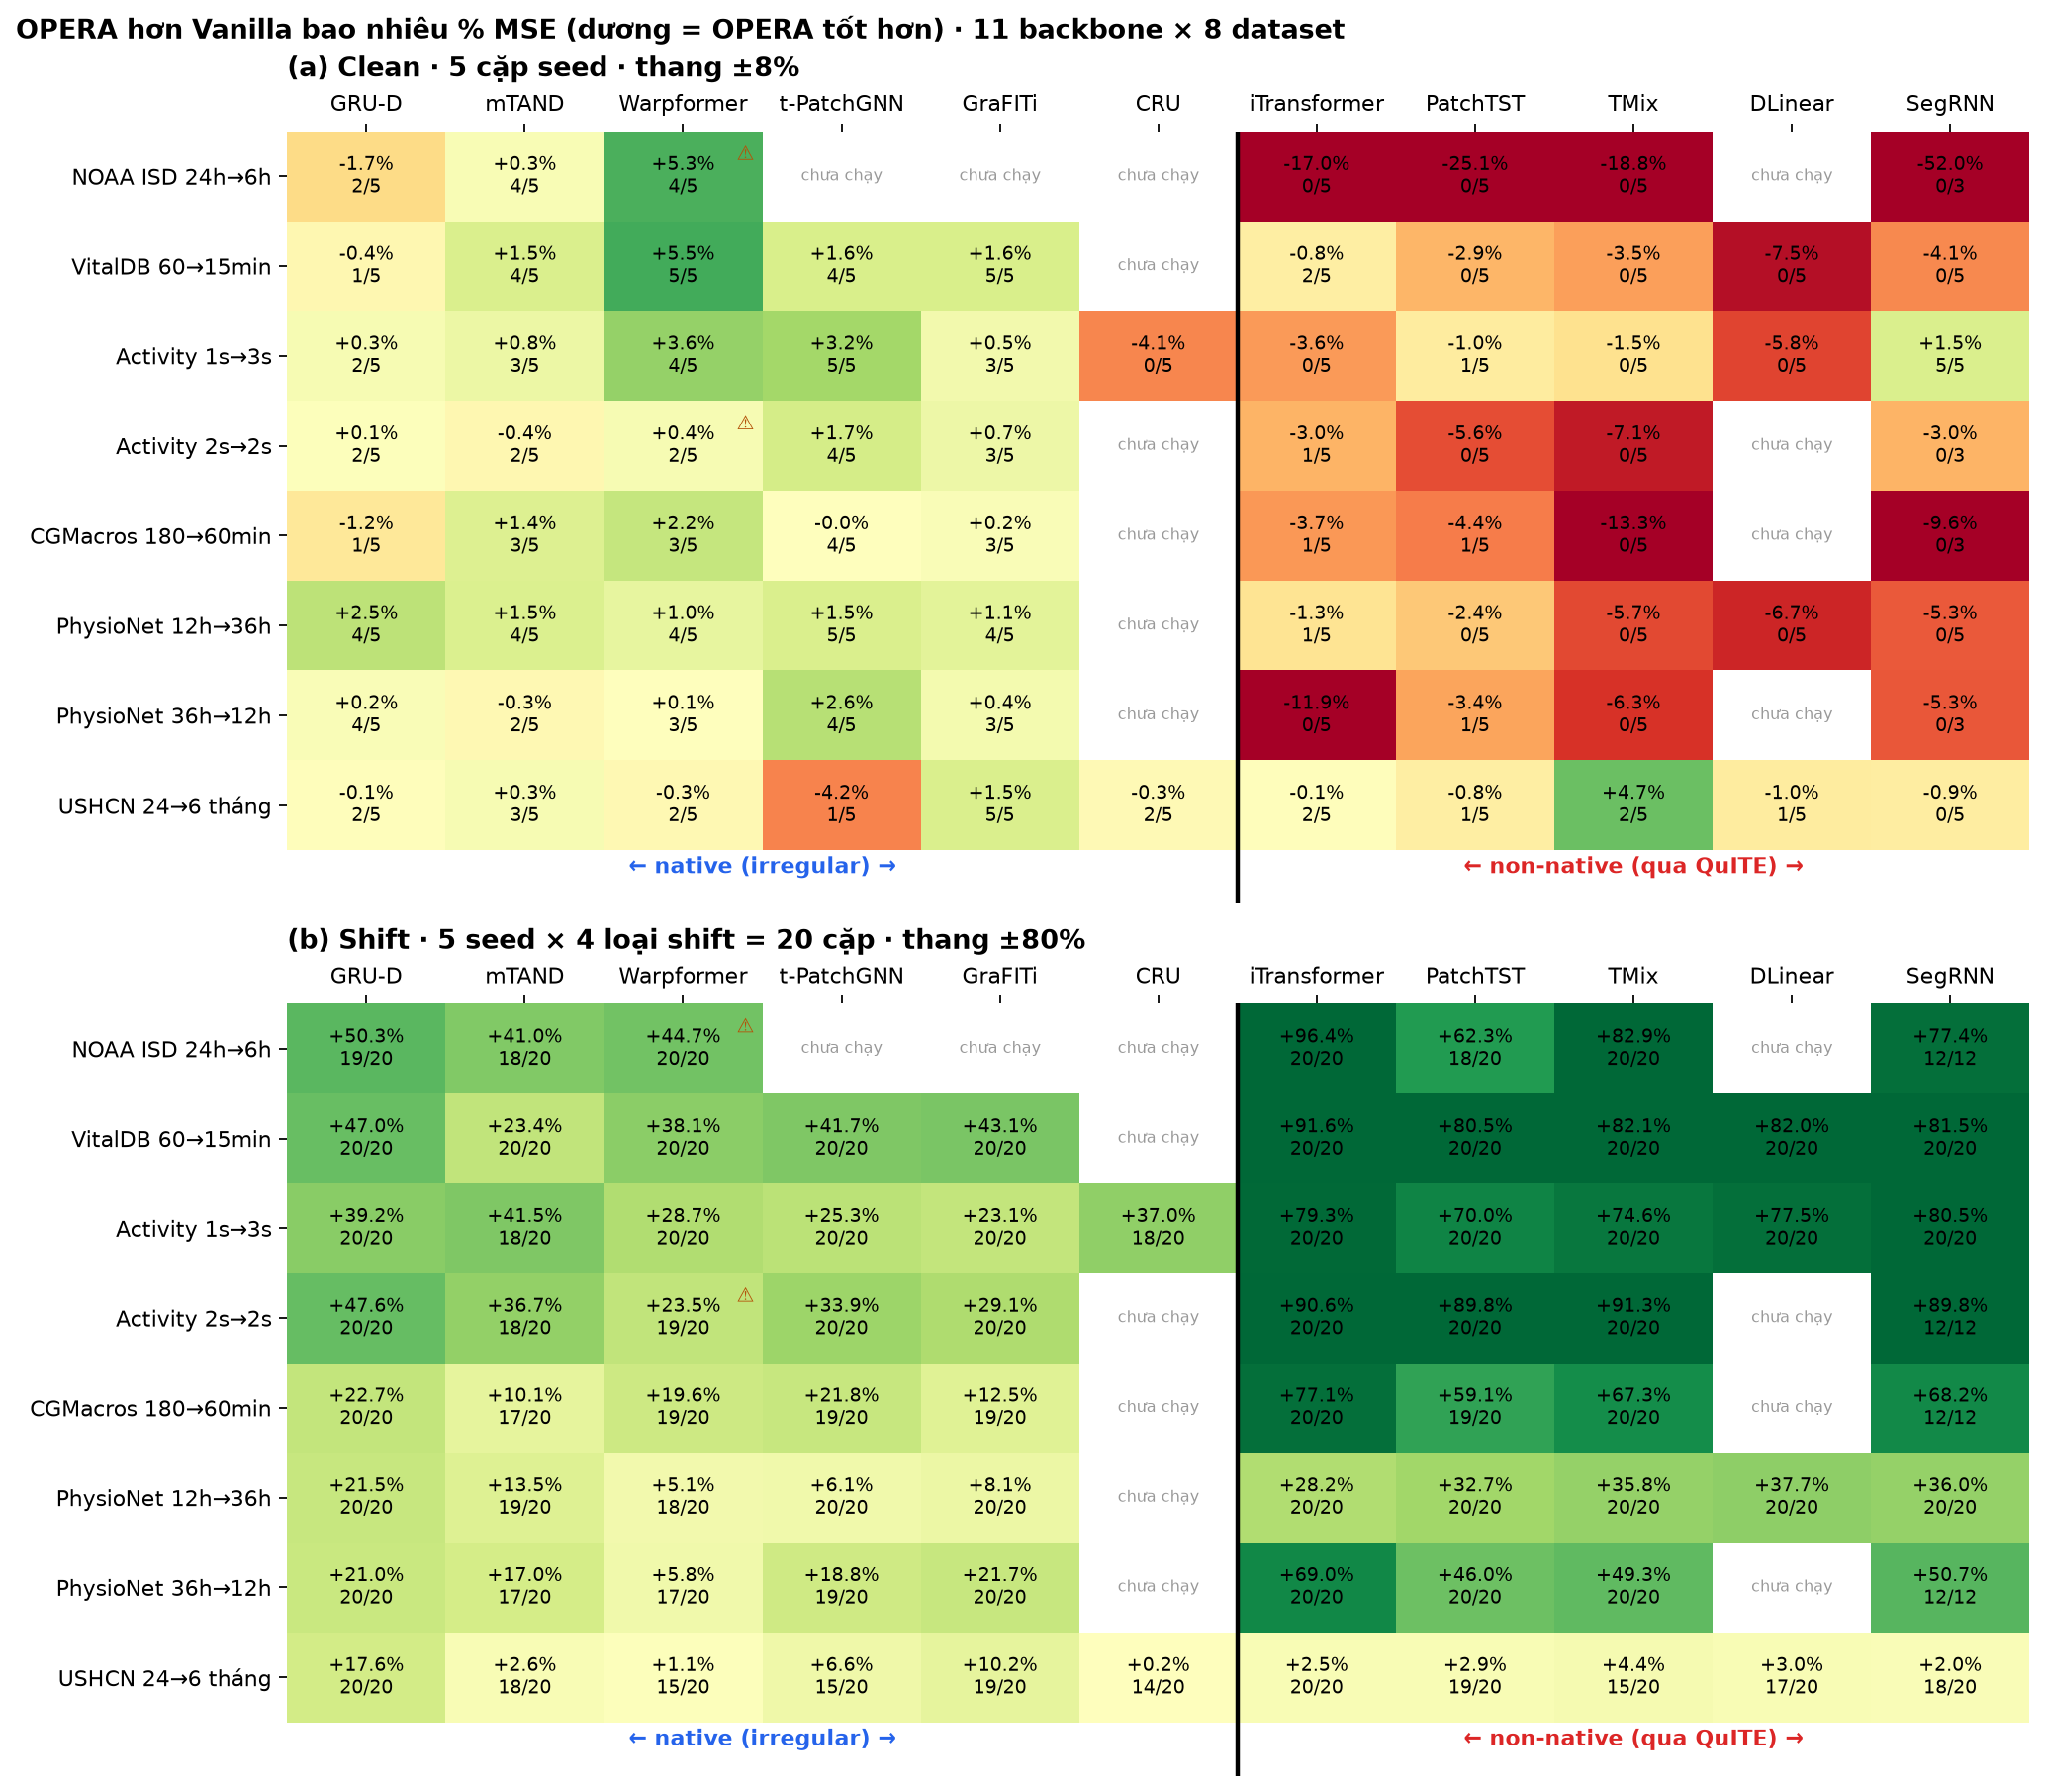

In [2]:
# Toàn cảnh: % OPERA hơn Vanilla ở mỗi ô dataset × backbone (trung bình các cặp seed [× loại shift]).
cell = pa.groupby(['part', 'dataset', 'backbone']).agg(gain=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size')).reset_index()
cols = list(BB)
fig, axes = plt.subplots(2, 1, figsize=(13, 11.5))
for ax, part, lim in zip(axes, ['clean', 'shift'], [8, 80]):
    d = cell[cell.part.eq(part)].set_index(['dataset', 'backbone'])
    G = d.gain.unstack().reindex(index=DS, columns=cols)
    ax.imshow(np.ma.masked_invalid(G.values), cmap='RdYlGn', vmin=-lim, vmax=lim, aspect='auto')
    for i, s in enumerate(DS):
        for j, b in enumerate(cols):
            if (s, b) in d.index:
                r = d.loc[(s, b)]
                ax.text(j, i, f'{r.gain:+.1f}%\n{r.w}/{r.n}', ha='center', va='center', fontsize=8.5)
            else:
                ax.text(j, i, 'chưa chạy', ha='center', va='center', fontsize=7, color='#999')
    for _, r in nanrun.drop_duplicates(['dataset', 'backbone']).iterrows():
        ax.text(cols.index(r.backbone) + .45, DS.index(r.dataset) - .35, '⚠', ha='right', va='top', fontsize=9, color='#b45309')
    ax.axvline(len(NATIVE) - .5, color='black', lw=2)
    ax.set_xticks(range(len(cols)), BB.values()); ax.set_yticks(range(len(DS)), [NAME[s] for s in DS])
    ax.xaxis.tick_top()
    ax.text(len(NATIVE) / 2 - .5, len(DS) - .43, '← native (irregular) →', ha='center', va='top', fontweight='bold', color='#2563eb')
    ax.text(len(NATIVE) + len(NONNAT) / 2 - .5, len(DS) - .43, '← non-native (qua QuITE) →', ha='center', va='top', fontweight='bold', color='#dc2626')
    ax.set_ylim(len(DS) + .1, -.5)
    ax.set_title({'clean': '(a) Clean · 5 cặp seed · thang ±8%', 'shift': '(b) Shift · 5 seed × 4 loại shift = 20 cặp · thang ±80%'}[part],
                 loc='left', fontweight='bold', pad=8)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle('OPERA hơn Vanilla bao nhiêu % MSE (dương = OPERA tốt hơn) · 11 backbone × 8 dataset', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'tong_ket_fig1_1_win_map')


**Kết luận:** (b) xanh ở mọi ô, cột non-native đậm hơn (+58 đến +96%). Hàng VitalDB giờ đủ 11 cột nhờ các run iTransformer / PatchTST / TMix trên VitalDB (trước nằm riêng ở `plugin_vitaldb`), và SegRNN có thêm 4 dataset (3 seed). (a) hai nửa vẫn tách rõ: native gần như vàng (hòa) với hai ô cam (CRU · Activity, t-PatchGNN · USHCN); non-native gần như toàn cam/đỏ, đậm nhất ở hàng NOAA.

<a id="bang-1-2"></a>

#### 📋 Bảng 1.2 · Gộp theo backbone

- Mỗi dataset cho 1 giá trị (trung bình các cặp), rồi lấy **trung vị qua các dataset**. **Vanilla tụt khi shift** = MSE shift ÷ MSE clean của Vanilla − 1. **commit** = commit code của các run.

In [3]:
# Gộp theo backbone: mỗi dataset 1 giá trị (trung bình các cặp), rồi lấy trung vị qua các dataset.
cd = pa.groupby(['family', 'backbone', 'dataset', 'part']).agg(gain=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size'),
                                                              vd=('vanilla_delta', 'mean')).reset_index()
rows = []
for b in BB:
    c, x = cd[cd.backbone.eq(b) & cd.part.eq('clean')], cd[cd.backbone.eq(b) & cd.part.eq('shift')]
    xs = pa[pa.backbone.eq(b) & pa.part.eq('shift')].groupby(['dataset', 'seed']).win.mean()   # thắng shift theo seed: thắng ≥ 3/4 loại?
    rows.append({'backbone': BB[b], 'nhóm': 'native' if b in NATIVE else 'non-native',
                 'commit': '/'.join(sorted(runs[runs.backbone.eq(b)].commit.unique())), 'số dataset': len(c),
                 'clean: OPERA hơn (trung vị)': f'{c.gain.median():+.1f}%',
                 'clean: dataset thắng / thua': f'{(c.gain > 0).sum()} / {(c.gain < 0).sum()}',
                 'clean: cặp thắng': f'{mark(c.w.sum(), c.n.sum())} {c.w.sum()}/{c.n.sum()}',
                 'shift: OPERA hơn (trung vị)': f'{x.gain.median():+.1f}%',
                 'shift: cặp thắng': f'{mark(x.w.sum(), x.n.sum())} {x.w.sum()}/{x.n.sum()}',
                 'Vanilla tụt khi shift (trung vị)': f'+{x.vd.median():.0f}%'})
tab12 = pd.DataFrame(rows).set_index('backbone')
display(tab12)


,nhóm,commit,số dataset,clean: OPERA hơn (trung vị),clean: dataset thắng / thua,clean: cặp thắng,shift: OPERA hơn (trung vị),shift: cặp thắng,Vanilla tụt khi shift (trung vị)
backbone,,,,,,,,,
GRU-D,native,e606587,8,-0.0%,4 / 4,⚪ 18/40,+31.0%,🟢 159/160,+144%
mTAND,native,e606587,8,+0.5%,6 / 2,⚪ 25/40,+20.2%,🟢 145/160,+76%
Warpformer,native,e606587,8,+1.6%,7 / 1,⚪ 27/40,+21.6%,🟢 148/160,+43%
t-PatchGNN,native,e606587,7,+1.6%,5 / 2,⚪ 27/35,+21.8%,🟢 133/140,+111%
GraFITi,native,e606587,7,+0.7%,7 / 0,⚪ 26/35,+21.7%,🟢 138/140,+82%
CRU,native,e606587,2,-2.2%,0 / 2,🔴 2/10,+18.6%,🟢 32/40,+101%
iTransformer,non-native,062d811/ce9a1cc,8,-3.3%,0 / 8,🔴 7/40,+78.2%,🟢 160/160,+743%
PatchTST,non-native,062d811/ce9a1cc,8,-3.2%,0 / 8,🔴 4/40,+60.7%,🟢 156/160,+894%
TMix,non-native,062d811/ce9a1cc,8,-6.0%,1 / 7,🔴 2/40,+71.0%,🟢 155/160,+783%


**Kết luận:** mọi backbone thắng shift ≥ 80% số cặp (thấp nhất CRU 32/40, mTAND 145/160; còn lại ≥ 92%). Clean tách hai khối: 5/6 native có trung vị từ −0.0% đến +1.6% (CRU −2.2%), cả 5 non-native có trung vị âm (−3.2% đến −6.3%) và thắng nhiều nhất 1 dataset. Vanilla non-native tụt +541% đến +894% khi shift, native chỉ +43% đến +144%. Lưu ý commit: iTransformer / PatchTST / TMix ở `062d811` / `ce9a1cc`, mọi backbone khác ở `e606587`.

<a id="bang-1-2b"></a>

#### 📋 Bảng 1.2b · Bảng kết quả theo kiểu file 00 (MSE)

- Với **Clean** và **Shifted** (mỗi seed = trung bình 4 điều kiện test: density 0.7, timing k = 3, variables 0.5, composed), mỗi phần có hai bảng:
  1. **Giá trị và % cải thiện:** MSE mean ± std qua seed của Vanilla và OPERA; **% opera** = % cải thiện so với Vanilla, ghép cặp theo seed, **dương = tốt hơn**; **seed thắng opera** = số seed OPERA thắng. Hàng **AVERAGE** = trung bình % cải thiện qua các ô.
  2. **Tóm tắt theo backbone:** % cải thiện trung bình (qua dataset), seed thắng, seed thắng %, **ô thắng** = số dataset mà MSE trung bình của OPERA thấp hơn Vanilla.
- Ô nào chỉ có một phía (VitalDB · CRU) bị bỏ. Hàm `bang00` dùng chung cho §1 và §3.

In [4]:
# Bảng kết quả kiểu file 00: với clean và shifted, (1) giá trị mean ± std qua seed + % cải thiện so với Vanilla (ghép cặp theo seed,
# dương = tốt hơn) và số seed thắng, có hàng AVERAGE; (2) tóm tắt: % cải thiện trung bình, seed wins, seed win %, cell wins.
def bang00(s, keys, methods, lower=True, digits=5, by='method', title='', order=None, by_order=None, groups=None):
    """s: mỗi dòng = một run, cột keys + ['method', 'seed', 'clean', 'shift'] (shift = trung bình 4 điều kiện)."""
    sign = 1 if lower else -1
    f = f'{{:.{digits}f}}'.format
    for part, name in [('clean', 'Clean (không shift)'), ('shift', 'Shifted (trung bình 4 shift)')]:
        mean = s.pivot_table(index=keys, columns='method', values=part, aggfunc='mean')
        std = s.pivot_table(index=keys, columns='method', values=part, aggfunc='std')
        ms = [m for m in methods if m in mean.columns]
        tab = pd.DataFrame(index=mean.index)
        for m in ms:
            tab[m] = [f'{f(a)} ± {f(b)}' if pd.notna(a) else '' for a, b in zip(mean[m], std[m])]
        base = s[s.method.eq('vanilla')].set_index(keys + ['seed'])[part]
        summ = []
        for m in ms[1:]:
            p = s[s.method.eq(m)].set_index(keys + ['seed'])[part].to_frame('m').join(base.rename('v'), how='inner')
            p['imp'] = 100 * sign * (p.v - p.m) / p.v; p['win'] = p.imp > 0
            g = p.groupby(level=list(range(len(keys)))).agg(imp=('imp', 'mean'), w=('win', 'sum'), n=('win', 'size'))
            tab[f'% {m}'] = g.imp.round(2); tab[f'seed thắng {m}'] = [f'{int(a)}/{int(b)}' for a, b in zip(g.w.reindex(tab.index).fillna(0), g.n.reindex(tab.index).fillna(0))]
            cellwin = (sign * (mean['vanilla'] - mean[m]) > 0)
            pp = p.reset_index(); pp['cell_win'] = [cellwin.get(tuple(r[k] for k in keys) if len(keys) > 1 else r[keys[0]], False) for _, r in pp.iterrows()]
            gk = pp.groupby(by) if by != 'method' else [(m, pp)]
            for k, d in gk:
                cells = d.groupby(keys).agg(imp=('imp', 'mean'), cw=('cell_win', 'first'))
                summ.append({by: k, 'TB % cải thiện': f'{cells.imp.mean():+.2f}%', 'seed thắng': f'{int(d.win.sum())}/{len(d)}',
                             'seed thắng %': f'{100 * d.win.mean():.0f}%', 'ô thắng': f'{int(cells.cw.sum())}/{len(cells)}'})
            for gname, members in (groups or {}).items():      # dòng gộp nhóm
                d = pp[pp[by].isin(members)]; cells = d.groupby(keys).agg(imp=('imp', 'mean'), cw=('cell_win', 'first'))
                summ.append({by: gname, 'TB % cải thiện': f'{cells.imp.mean():+.2f}%', 'seed thắng': f'{int(d.win.sum())}/{len(d)}',
                             'seed thắng %': f'{100 * d.win.mean():.0f}%', 'ô thắng': f'{int(cells.cw.sum())}/{len(cells)}'})
        if order: tab = tab.loc[sorted(tab.index, key=order)]
        avg = {c: '' for c in tab.columns}
        avg.update({c: round(tab[c].mean(), 2) for c in tab.columns if c.startswith('% ')})
        tab.loc[('AVERAGE',) + ('',) * (len(keys) - 1) if len(keys) > 1 else 'AVERAGE', :] = pd.Series(avg)
        print(f'\n========== {title}{name} ==========')
        with pd.option_context('display.max_rows', 500): display(tab)
        sm = pd.DataFrame(summ).set_index(by)
        if by_order: sm = sm.reindex([x for x in by_order if x in sm.index] + [x for x in sm.index if x not in by_order])
        print('Tóm tắt' + (' theo backbone' if by == 'backbone' else ' theo phương pháp')); display(sm)


In [5]:
# §1 theo kiểu file 00: MSE, 8 setting chính × 11 backbone, Vanilla vs OPERA.
s1 = runs.assign(clean=runs['mse[identity]'], shift=runs[[f'mse[{c}]' for c in COND]].mean(axis=1))
s1 = s1[s1.groupby(['dataset', 'backbone']).method.transform('nunique').eq(2)]          # chỉ ô có cả hai phía
s1 = s1.assign(backbone=s1.backbone.map(BB), dataset=s1.dataset.map(NAME))           # tên hiển thị
bang00(s1, ['backbone', 'dataset'], ['vanilla', 'opera'], lower=True, digits=5, by='backbone', title='MSE — ',
       order=lambda k: (list(BB.values()).index(k[0]), [NAME[x] for x in DS].index(k[1])), by_order=list(BB.values()),
       groups={'TB native': list(NATIVE.values()), 'TB non-native': list(NONNAT.values())})



========== MSE — Clean (không shift) ==========


vanilla              opera  % opera seed thắng opera
backbone     dataset                                                                           
GRU-D        NOAA ISD 24h→6h     0.00072 ± 0.00002  0.00074 ± 0.00004    -1.71              2/5
             VitalDB 60→15min    0.00259 ± 0.00002  0.00260 ± 0.00001    -0.39              1/5
             Activity 1s→3s      0.00492 ± 0.00009  0.00491 ± 0.00007     0.34              2/5
             Activity 2s→2s      0.00387 ± 0.00007  0.00387 ± 0.00005     0.09              2/5
             CGMacros 180→60min  0.00394 ± 0.00008  0.00398 ± 0.00004    -1.19              1/5
             PhysioNet 12h→36h   0.00632 ± 0.00023  0.00616 ± 0.00012     2.49              4/5
             PhysioNet 36h→12h   0.00462 ± 0.00026  0.00461 ± 0.00019     0.24              4/5
             USHCN 24→6 tháng    0.52867 ± 0.00248  0.52933 ± 0.00419    -0.12              2/5
mTAND        NOAA ISD 24h→6h     0.00080 ± 0.00004  0.00079 ± 0.00003     0.27              4/5
             VitalDB 60→15min    0.00274 ± 0.00005  0.00270 ± 0.00003     1.54              4/5
             Activity 1s→3s      0.00485 ± 0.00007  0.00482 ± 0.00010     0.76              3/5
             Activity 2s→2s      0.00391 ± 0.00006  0.00392 ± 0.00005    -0.43              2/5
             CGMacros 180→60min  0.00442 ± 0.00014  0.00436 ± 0.00004     1.42              3/5
             PhysioNet 12h→36h   0.00658 ± 0.00023  0.00649 ± 0.00016     1.45              4/5
             PhysioNet 36h→12h   0.00586 ± 0.00033  0.00587 ± 0.00031    -0.33              2/5
             USHCN 24→6 tháng    0.58301 ± 0.08497  0.58121 ± 0.08631     0.34              3/5
Warpformer   NOAA ISD 24h→6h     0.00343 ± 0.00048  0.00321 ± 0.00008     5.32              4/5
             VitalDB 60→15min    0.00399 ± 0.00021  0.00377 ± 0.00008     5.53              5/5
             Activity 1s→3s      0.01122 ± 0.00075  0.01080 ± 0.00035     3.57              4/5
             Activity 2s→2s      0.00989 ± 0.00149  0.00974 ± 0.00063     0.36              2/5
             CGMacros 180→60min  0.00769 ± 0.00035  0.00750 ± 0.00007     2.21              3/5
             PhysioNet 12h→36h   0.00823 ± 0.00011  0.00815 ± 0.00009     0.99              4/5
             PhysioNet 36h→12h   0.00776 ± 0.00039  0.00773 ± 0.00039     0.05              3/5
             USHCN 24→6 tháng    0.56454 ± 0.01554  0.56656 ± 0.01835    -0.35              2/5
t-PatchGNN   VitalDB 60→15min    0.00261 ± 0.00006  0.00257 ± 0.00003     1.60              4/5
             Activity 1s→3s      0.00464 ± 0.00005  0.00449 ± 0.00006     3.25              5/5
             Activity 2s→2s      0.00352 ± 0.00011  0.00346 ± 0.00013     1.70              4/5
             CGMacros 180→60min  0.00409 ± 0.00006  0.00410 ± 0.00007    -0.04              4/5
             PhysioNet 12h→36h   0.00592 ± 0.00007  0.00583 ± 0.00006     1.51              5/5
             PhysioNet 36h→12h   0.00423 ± 0.00023  0.00411 ± 0.00011     2.63              4/5
             USHCN 24→6 tháng    0.52589 ± 0.01177  0.54871 ± 0.04318    -4.24              1/5
GraFITi      VitalDB 60→15min    0.00245 ± 0.00007  0.00241 ± 0.00002     1.58              5/5
             Activity 1s→3s      0.00451 ± 0.00011  0.00449 ± 0.00009     0.53              3/5
             Activity 2s→2s      0.00360 ± 0.00005  0.00358 ± 0.00008     0.70              3/5
             CGMacros 180→60min  0.00429 ± 0.00005  0.00428 ± 0.00008     0.22              3/5
             PhysioNet 12h→36h   0.00576 ± 0.00005  0.00570 ± 0.00005     1.14              4/5
             PhysioNet 36h→12h   0.00456 ± 0.00008  0.00454 ± 0.00012     0.44              3/5
             USHCN 24→6 tháng    0.50320 ± 0.00500  0.49561 ± 0.00401     1.50              5/5
CRU          Activity 1s→3s      0.00565 ± 0.00012  0.00588 ± 0.00018    -4.15              0/5
             USHCN 24→6 tháng    0.73143 ± 0.00585  0.73368 ± 0.00417    -0.31              2/5
iTransforme

Tóm tắt theo backbone


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
backbone,,,,
GRU-D,-0.03%,18/40,45%,4/8
mTAND,+0.63%,25/40,62%,6/8
Warpformer,+2.21%,27/40,68%,7/8
t-PatchGNN,+0.92%,27/35,77%,5/7
GraFITi,+0.87%,26/35,74%,7/7
CRU,-2.23%,2/10,20%,0/2
iTransformer,-5.17%,7/40,18%,0/8
PatchTST,-5.70%,4/40,10%,0/8
TMix,-6.45%,2/40,5%,1/8



========== MSE — Shifted (trung bình 4 shift) ==========


vanilla              opera  % opera seed thắng opera
backbone     dataset                                                                           
GRU-D        NOAA ISD 24h→6h     0.00818 ± 0.00230  0.00188 ± 0.00010    75.32              5/5
             VitalDB 60→15min    0.00820 ± 0.00180  0.00323 ± 0.00001    59.09              5/5
             Activity 1s→3s      0.01360 ± 0.00072  0.00685 ± 0.00009    49.52              5/5
             Activity 2s→2s      0.01981 ± 0.00094  0.00546 ± 0.00005    72.36              5/5
             CGMacros 180→60min  0.00831 ± 0.00034  0.00621 ± 0.00010    25.22              5/5
             PhysioNet 12h→36h   0.00953 ± 0.00061  0.00736 ± 0.00011    22.55              5/5
             PhysioNet 36h→12h   0.00776 ± 0.00022  0.00586 ± 0.00018    24.35              5/5
             USHCN 24→6 tháng    0.73338 ± 0.02276  0.59889 ± 0.00929    18.30              5/5
mTAND        NOAA ISD 24h→6h     0.00919 ± 0.00505  0.00190 ± 0.00005    74.91              5/5
             VitalDB 60→15min    0.00521 ± 0.00033  0.00321 ± 0.00002    38.14              5/5
             Activity 1s→3s      0.01386 ± 0.00133  0.00618 ± 0.00029    55.18              5/5
             Activity 2s→2s      0.01214 ± 0.00077  0.00514 ± 0.00024    57.48              5/5
             CGMacros 180→60min  0.00715 ± 0.00035  0.00626 ± 0.00001    12.21              5/5
             PhysioNet 12h→36h   0.00867 ± 0.00032  0.00738 ± 0.00015    14.76              5/5
             PhysioNet 36h→12h   0.00859 ± 0.00026  0.00680 ± 0.00027    20.77              5/5
             USHCN 24→6 tháng    0.64534 ± 0.06003  0.62820 ± 0.06789     2.75              5/5
Warpformer   NOAA ISD 24h→6h     0.00804 ± 0.00291  0.00378 ± 0.00015    49.64              5/5
             VitalDB 60→15min    0.00722 ± 0.00053  0.00402 ± 0.00004    44.06              5/5
             Activity 1s→3s      0.01665 ± 0.00173  0.01157 ± 0.00034    29.74              5/5
             Activity 2s→2s      0.01426 ± 0.00078  0.01025 ± 0.00045    27.89              5/5
             CGMacros 180→60min  0.01069 ± 0.00066  0.00845 ± 0.00024    20.72              5/5
             PhysioNet 12h→36h   0.00912 ± 0.00017  0.00865 ± 0.00009     5.19              5/5
             PhysioNet 36h→12h   0.00872 ± 0.00022  0.00819 ± 0.00037     5.98              4/5
             USHCN 24→6 tháng    0.59583 ± 0.01688  0.58906 ± 0.01972     1.15              5/5
t-PatchGNN   VitalDB 60→15min    0.01036 ± 0.00070  0.00322 ± 0.00008    68.83              5/5
             Activity 1s→3s      0.01160 ± 0.00495  0.00692 ± 0.00047    31.24              5/5
             Activity 2s→2s      0.01162 ± 0.00534  0.00507 ± 0.00028    48.25              5/5
             CGMacros 180→60min  0.00864 ± 0.00126  0.00632 ± 0.00010    25.79              5/5
             PhysioNet 12h→36h   0.00777 ± 0.00020  0.00727 ± 0.00012     6.43              5/5
             PhysioNet 36h→12h   0.00756 ± 0.00076  0.00576 ± 0.00012    23.34              5/5
             USHCN 24→6 tháng    0.65969 ± 0.03640  0.60472 ± 0.04250     8.21              5/5
GraFITi      VitalDB 60→15min    0.00965 ± 0.00102  0.00297 ± 0.00003    68.94              5/5
             Activity 1s→3s      0.00999 ± 0.00206  0.00691 ± 0.00017    28.94              5/5
             Activity 2s→2s      0.01183 ± 0.00544  0.00595 ± 0.00011    42.73              5/5
             CGMacros 180→60min  0.00737 ± 0.00019  0.00634 ± 0.00017    13.98              5/5
             PhysioNet 12h→36h   0.00757 ± 0.00014  0.00693 ± 0.00008     8.50              5/5
             PhysioNet 36h→12h   0.00830 ± 0.00060  0.00589 ± 0.00012    28.69              5/5
             USHCN 24→6 tháng    0.61019 ± 0.01280  0.54419 ± 0.01515    10.79              5/5
CRU          Activity 1s→3s      0.01693 ± 0.00164  0.00846 ± 0.00024    49.69              5/5
             USHCN 24→6 tháng    0.74992 ± 0.00342  0.74801 ± 0.00135     0.25              4/5
iTransforme

Tóm tắt theo backbone


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
backbone,,,,
GRU-D,+43.34%,40/40,100%,8/8
mTAND,+34.52%,40/40,100%,8/8
Warpformer,+23.05%,39/40,98%,8/8
t-PatchGNN,+30.30%,35/35,100%,7/7
GraFITi,+28.94%,35/35,100%,7/7
CRU,+24.97%,9/10,90%,2/2
iTransformer,+67.64%,40/40,100%,8/8
PatchTST,+56.33%,40/40,100%,8/8
TMix,+61.35%,39/40,98%,8/8


**Kết luận (đọc bảng Tóm tắt theo backbone):**
- **Clean:** native gần hòa, TB native **+0.76%** (125/200 seed, 29/40 ô); GraFITi 7/7 ô, Warpformer 7/8, mTAND 6/8; CRU −2.23% (0/2). Non-native kém đi, TB **−6.62%** (19/172 seed, chỉ 2/36 ô); tệ nhất SegRNN −9.83% (NOAA −52%, 3 seed).
- **Shifted:** OPERA thắng **40/40 ô native và 36/36 ô non-native**; seed thắng 198/200 và 171/172. TB native **+31.8%** (Warpformer +23.1% đến GRU-D +43.3%), non-native **+60.4%** (DLinear +50.3% đến iTransformer +67.6%).
- Lưu ý: cột Shifted ở đây theo cách của file 00, tức % cải thiện trên **MSE trung bình 4 shift** của mỗi seed. Cách này bị loại shift nặng nhất (variables) chi phối, nên số lớn hơn Bảng 1.2 (trung vị của % từng loại shift; ví dụ GRU-D +43.3% so với +31.0%). Khi viết paper, chọn một cách và ghi rõ.

<a id="hinh-1-3"></a>

#### 📈 Hình 1.3 · Chi phí clean đi theo nhóm backbone

- Mỗi điểm = dataset × backbone (trung bình các seed). Xanh = native, đỏ = non-native. **Trục x:** MSE shift ÷ MSE clean của Vanilla (log). **Trục y:** % OPERA hơn Vanilla khi clean (âm = OPERA kém hơn).

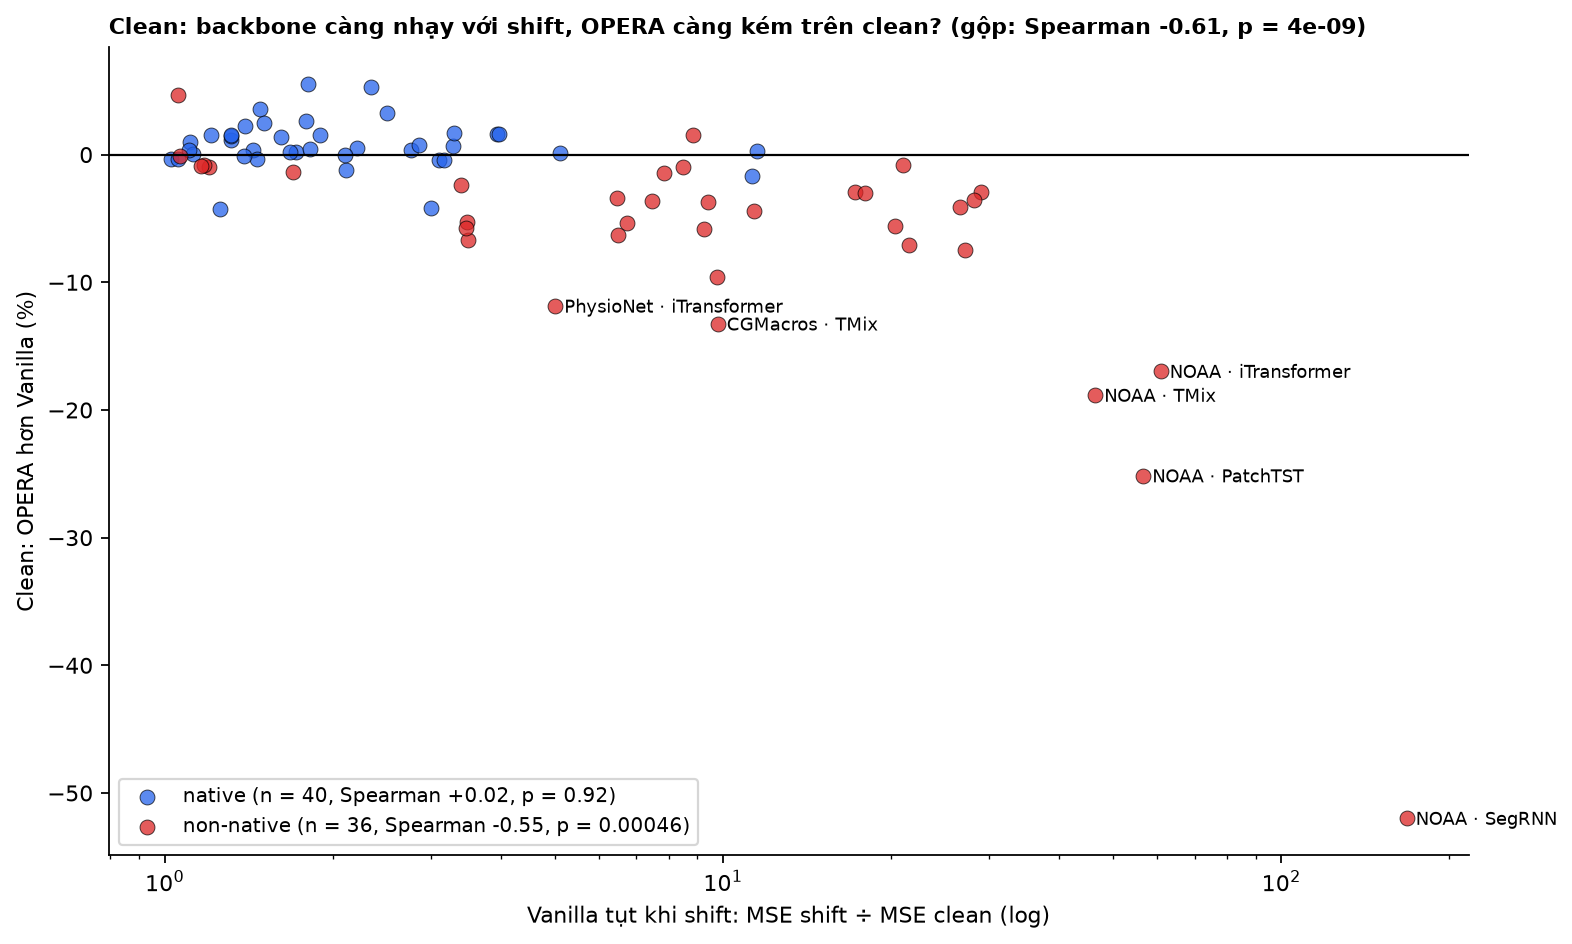

In [6]:
# Mỗi điểm = dataset × backbone (trung bình 5 seed). x = Vanilla tụt khi shift (MSE shift trung bình 4 loại ÷ MSE clean),
# y = % OPERA hơn Vanilla khi clean. Spearman tính chung và tính riêng từng nhóm.
q = pa.groupby(['family', 'dataset', 'backbone', 'part'])[['vanilla', 'opera', 'gain']].mean().unstack('part')
pp = pd.DataFrame({'sens': q[('vanilla', 'shift')] / q[('vanilla', 'clean')],
                   'clean_gain': q[('gain', 'clean')]}).reset_index()
FC = {'native': '#2563eb', 'non-native': '#dc2626'}
fig, ax = plt.subplots(figsize=(10, 6))
for fam, g in pp.groupby('family'):
    ax.scatter(g.sens, g.clean_gain, s=45, color=FC[fam], alpha=.75, ec='black', lw=.4,
               label=f'{fam} (n = {len(g)}, Spearman {spearmanr(g.sens, g.clean_gain)[0]:+.2f}, p = {spearmanr(g.sens, g.clean_gain)[1]:.2g})')
for r in pp[pp.clean_gain < -10].itertuples():
    ax.annotate(f'{NAME[r.dataset].split()[0]} · {BB[r.backbone]}', (r.sens, r.clean_gain), xytext=(4, -3), textcoords='offset points', fontsize=8)
rho_all = spearmanr(pp.sens, pp.clean_gain)
ax.axhline(0, color='black', lw=1); ax.set_xscale('log')
ax.set_xlabel('Vanilla tụt khi shift: MSE shift ÷ MSE clean (log)'); ax.set_ylabel('Clean: OPERA hơn Vanilla (%)')
ax.set_title(f'Clean: backbone càng nhạy với shift, OPERA càng kém trên clean? (gộp: Spearman {rho_all[0]:+.2f}, p = {rho_all[1]:.1g})',
             loc='left', fontweight='bold', fontsize=10)
ax.legend(loc='lower left', fontsize=9)
fig.tight_layout()
save(fig, 'tong_ket_fig1_3_sensitivity_vs_clean')


<a id="bang-1-4"></a>

#### 📋 Bảng 1.4 · Số liệu cho Hình 1.3

- **(a)** % OPERA hơn Vanilla khi clean theo khoảng mức nhạy, và trong **vùng chồng nhau** (mức nhạy mà cả hai nhóm cùng có). **(b)** Non-native theo dataset, kèm MSE clean của Vanilla so với native tốt nhất cùng dataset.

In [7]:
# Số liệu cho Hình 1.3: so hai nhóm ở cùng mức nhạy, và non-native theo dataset.
pp['V_clean'] = q[('vanilla', 'clean')].values
fmt = lambda g: f"{g.clean_gain.median():+.1f}% [{g.clean_gain.min():+.1f} … {g.clean_gain.max():+.1f}] (n={len(g)})"
pp['khoảng nhạy'] = pd.cut(pp.sens, [1, 2, 5, 10, 100], labels=['×1–2', '×2–5', '×5–10', '×10–61'])
ta = pp.groupby(['khoảng nhạy', 'family'], observed=True).apply(fmt, include_groups=False).unstack('family')
lo, hi = pp[pp.family.eq('non-native')].sens.min(), pp[pp.family.eq('native')].sens.max()
ta.loc[f'vùng chồng nhau ×{lo:.2f}–{hi:.1f}'] = pp[pp.sens.between(lo, hi)].groupby('family').apply(fmt, include_groups=False)
print('(a) Clean: OPERA hơn Vanilla — trung vị [min … max] (số ô), theo khoảng Vanilla tụt khi shift'); display(ta)
nn = pp[pp.family.eq('non-native')].copy()
nn['rel'] = nn.V_clean / nn.dataset.map(pp[pp.family.eq('native')].groupby('dataset').V_clean.min())
tb = nn.groupby('dataset').agg(**{'số bb': ('backbone', 'size'), 'Vanilla tụt (MSE shift ÷ clean, trung vị)': ('sens', 'median'),
                                  'clean: OPERA hơn (trung vị %)': ('clean_gain', 'median'),
                                  'MSE clean Vanilla ÷ native tốt nhất': ('rel', 'median')}).sort_values('Vanilla tụt (MSE shift ÷ clean, trung vị)')
tb['Spearman trong dataset'] = [spearmanr(nn[nn.dataset.eq(s)].sens, nn[nn.dataset.eq(s)].clean_gain)[0] if (nn.dataset == s).sum() >= 3 else np.nan for s in tb.index]
print('(b) Non-native theo dataset'); display(tb.rename(index=NAME).round(2))
dl = nn.groupby('dataset')[['sens', 'clean_gain']].median()
print(f'Spearman giữa các dataset: {spearmanr(dl.sens, dl.clean_gain)[0]:+.2f} · Spearman(MSE ÷ native tốt nhất, clean) trên {len(nn)} ô: {spearmanr(nn.rel, nn.clean_gain)[0]:+.2f}')


(a) Clean: OPERA hơn Vanilla — trung vị [min … max] (số ô), theo khoảng Vanilla tụt khi shift


family,native,non-native
khoảng nhạy,,
×1–2,+1.0% [-4.2 … +5.5] (n=23),-0.9% [-1.3 … +4.7] (n=6)
×2–5,+0.6% [-4.1 … +5.3] (n=14),-5.5% [-6.7 … -2.4] (n=4)
×5–10,+0.1% [+0.1 … +0.1] (n=1),-4.5% [-13.3 … +1.5] (n=12)
×10–61,-0.7% [-1.7 … +0.3] (n=2),-4.4% [-25.1 … -0.8] (n=13)
vùng chồng nhau ×1.06–11.5,+0.6% [-4.2 … +5.5] (n=38),-3.6% [-13.3 … +4.7] (n=23)


(b) Non-native theo dataset


,số bb,"Vanilla tụt (MSE shift ÷ clean, trung vị)",clean: OPERA hơn (trung vị %),MSE clean Vanilla ÷ native tốt nhất,Spearman trong dataset
dataset,,,,,
USHCN 24→6 tháng,5,1.16,-0.82,1.03,-0.9
PhysioNet 12h→36h,5,3.47,-5.31,3.06,-0.9
PhysioNet 36h→12h,4,6.47,-5.84,2.17,0.4
Activity 1s→3s,5,8.47,-1.46,1.07,0.0
CGMacros 180→60min,4,9.77,-6.99,1.11,-0.4
Activity 2s→2s,4,19.17,-4.27,1.07,-1.0
VitalDB 60→15min,5,27.12,-3.54,1.13,-0.1
NOAA ISD 24h→6h,4,58.79,-21.99,2.95,-0.4


Spearman giữa các dataset: -0.45 · Spearman(MSE ÷ native tốt nhất, clean) trên 36 ô: -0.51


**Đọc Hình 1.3 và Bảng 1.4:**

| # | Quan sát | Số liệu | Nghĩa là |
|---|---|---|---|
| 1 | **Hai nhóm nằm ở hai vùng khác nhau.** Native dồn bên trái quanh 0; non-native dồn bên phải, dưới 0 | Spearman gộp −0.61, nhưng native +0.02 (p = 0.92) và non-native −0.55 (p = 5e-4) | Số gộp chủ yếu là khoảng cách giữa hai cụm, không trích số này |
| 2 | **Ở cùng mức nhạy, non-native vẫn mất clean, native thì không** | Vùng chồng nhau ×1.06–11.5: native +0.6% (38 ô), non-native −3.6% (23 ô). Khoảng ×2–5: +0.6% so với −5.5% | Chi phí đi theo **cách backbone nhận input** (qua QuITE hay native) |
| 3 | **Bên trong native, mức nhạy không dự báo chi phí** | Ô nhạy nhất (NOAA · GRU-D ×11.3, mTAND ×11.5) chỉ −1.7% và +0.3%. Hai ô thua (CRU · Activity, t-PatchGNN · USHCN, cùng −4.2%) có mức nhạy thấp | Hai ô thua có nguyên nhân riêng (CRU thua cả 5 seed; t-PatchGNN do seed 0) |
| 4 | **Trong non-native, quan hệ chủ yếu nằm giữa các dataset** | Theo dataset: USHCN ×1.2 → −0.8%, NOAA ×59 → −22.0% (Spearman giữa 8 dataset −0.45). Trong cùng dataset, Spearman lúc âm lúc dương (−1.0 đến +0.4) | Không nói được "backbone nào nhạy hơn thì mất nhiều hơn"; chỉ nói được dataset nào làm token QuITE đổi mạnh thì chi phí lớn |
| 5 | **Một phần chi phí đi kèm model yếu sẵn** | MSE clean Vanilla non-native so với native tốt nhất: NOAA ×2.95, PhysioNet 12h ×3.06, PhysioNet 36h ×2.17, còn lại ×1.03–1.13. Spearman(tỉ số này, clean) −0.51 | Ô thua nặng nhất (NOAA, tới −52% với SegRNN 3 seed) là chỗ non-native đã kém native ~3 lần; nhưng PhysioNet 12h cũng ~3 lần mà chỉ −1% đến −7% |
| 6 | **Nơi Vanilla không bị shift làm hại thì OPERA cũng không làm hại** | USHCN (×1.06–1.20): non-native từ −1.0% đến +4.7% | Chi phí clean xuất hiện cùng lúc với mức sụp của Vanilla |

**Kết luận:** chi phí clean là **tính chất của nhóm non-native qua QuITE**, lớn ở những dataset làm Vanilla sụp mạnh (NOAA nhất). Với native, chi phí gần như bằng 0 ở mọi mức nhạy. Giả thuyết (chưa kiểm chứng): student không bao giờ thấy view sạch (`identity` không có trong pool train); kiểm bằng cách thêm `identity` vào pool (`TONG_KET.md` §4.1).

<a id="bang-1-5"></a>

#### 📋 Bảng 1.5 · Setting phụ trong gói 18/11

- Các setting tên cũ (`activity`, `physionet`, `ushcn_1mo`, `ushcn_12mo`), chủ yếu SegRNN 3 seed. Để riêng vì không cùng bộ 8 setting chính.

In [8]:
# Setting phụ có trong gói 18/11 (tên setting cũ, phần lớn chỉ SegRNN 3 seed): đặt riêng, không gộp vào §1.
x = pall[~pall.dataset.isin(DS)]
t = x.groupby(['dataset', 'backbone', 'part']).agg(g=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size')).reset_index()
t['txt'] = [f'{mark(r.w, r.n)} {r.g:+.1f}% ({r.w}/{r.n})' for r in t.itertuples()]
t = t.pivot(index=['dataset', 'backbone'], columns='part', values='txt').rename(columns={'clean': 'clean: OPERA hơn', 'shift': 'shift: OPERA hơn'})
t['số seed'] = x[x.part.eq('clean')].groupby(['dataset', 'backbone']).size()
t = t.reset_index(); t['backbone'] = t.backbone.map(BB)
display(t.set_index(['dataset', 'backbone']))


part                    clean: OPERA hơn  shift: OPERA hơn  số seed
dataset    backbone                                                
activity   iTransformer    🔴 -7.0% (0/1)    🟢 +94.1% (4/4)        1
           PatchTST        🔴 -7.0% (0/1)    🟢 +92.6% (4/4)        1
           SegRNN          🔴 -8.4% (0/3)  🟢 +92.6% (12/12)        3
           TMix            🔴 -9.5% (0/1)    🟢 +93.9% (4/4)        1
physionet  SegRNN          🔴 -5.9% (0/3)  🟢 +44.6% (12/12)        3
ushcn_12mo SegRNN          🔴 -1.0% (0/3)   🟢 +2.4% (11/12)        3
ushcn_1mo  SegRNN          ⚪ -1.0% (1/3)    ⚪ +2.3% (9/12)        3

**Kết luận:** các setting tên cũ cho cùng hình ảnh với non-native ở §1: thua clean (−6% đến −10% ở activity / physionet, ≈ −1% ở USHCN), thắng shift rất lớn ở activity (+93%) và physionet (+45%), nhỏ ở USHCN (+2.3–2.4%). iTransformer / PatchTST / TMix ở `activity` chỉ có seed 0, chỉ để tham khảo.

<a id="phan-2"></a>

# 2. Đường cong theo mức nặng (severity sweep)

[↑ Tóm tắt](#summary)

- **Mốc chung** = MSE của Vanilla lúc sạch (cùng dataset, backbone, seed). Trục y = (MSE Vanilla sạch − MSE) ÷ MSE Vanilla sạch: **0 = bằng Vanilla lúc sạch, âm = tệ hơn**. Vùng xám = mức có trong mixture train. **Số xanh (trên) = OPERA, số cam (dưới) = Vanilla**; vùng vàng = khoảng cách.
- Gộp: trung bình seed trong mỗi ô dataset × backbone, rồi trung bình hình học tỉ số MSE qua các ô. Chỉ dùng 8 setting chính.

In [9]:
# Severity sweep (gói 18/11): mỗi run đánh giá lại ở 20 điều kiện, KHÔNG train lại, Vanilla và OPERA cùng input (seed 12345).
FAM = {'random_dropout': 'density (xóa ngẫu nhiên)', 'temporal_stride': 'timing (giữ 1/k mốc)',
       'variable_dropout': 'variables (xóa biến)', 'composed': 'composed (stride 3 + xóa nhóm biến)'}
SEEN = {'random_dropout': 0.4, 'temporal_stride': 2, 'variable_dropout': 0.2, 'composed': None}
def parse(c):
    if c == 'identity':
        return [('random_dropout', 0.0), ('temporal_stride', 1.0), ('variable_dropout', 0.0), ('composed', -1.0)]
    if c == 'temporal_stride:3':
        return [('temporal_stride', 3.0), ('composed', 0.0)]
    if c.startswith('temporal_stride:3+variable_group_dropout:'):
        return [('composed', float(c.split(':')[-1]))]
    f, val = c.split(':'); return [(f, float(val))]
rows = []
for f in sorted(SWEEPD.glob('*.json')):
    j = json.loads(f.read_text()); m = re.match(RUNRE, j['run'])
    for c, val in j['per_condition'].items():
        for fam, sv in parse(c):
            rows.append({'dataset': m[1], 'backbone': m[2], 'method': m[3], 'seed': int(m[4]), 'condition': c,
                         'family': fam, 'severity': sv, 'mse': val['mse']})
sev = pd.DataFrame(rows)
sev.drop_duplicates(KEY + ['condition'])[KEY + ['condition', 'mse']].to_csv(MERGED / 'sweep_long.csv', index=False)
chk = sev.drop_duplicates(KEY + ['condition']).merge(long.rename(columns={'mse': 'mse_main'}), on=KEY + ['condition'])
print(f'{sev[KEY].drop_duplicates().shape[0]} run · {sev.condition.nunique()} điều kiện · khớp per_run ở {len(chk)} điểm protocol, '
      f'sai khác tương đối lớn nhất {(chk.mse / chk.mse_main - 1).abs().max():.1e}')
sp = sev.pivot_table(index=['dataset', 'backbone', 'seed', 'family', 'severity'], columns='method', values='mse').dropna().reset_index()
vc = sev[sev.condition.eq('identity') & sev.method.eq('vanilla')].drop_duplicates(KEY).set_index(['dataset', 'backbone', 'seed']).mse.rename('vanilla_clean')
sp = sp.join(vc, on=['dataset', 'backbone', 'seed'])
oc = sev[sev.condition.eq('identity') & sev.method.eq('opera')].drop_duplicates(KEY).set_index(['dataset', 'backbone', 'seed']).mse.rename('opera_clean')
sp = sp.join(oc, on=['dataset', 'backbone', 'seed'])
sp['r_v'], sp['o_vc'] = sp.vanilla / sp.vanilla_clean, sp.opera / sp.vanilla_clean
sp['r_o'] = sp.opera / sp.opera_clean                       # OPERA so với lúc sạch của chính nó
sp['gain'] = 100 * (sp.vanilla - sp.opera) / sp.vanilla     # OPERA hơn Vanilla ở cùng mức, cùng seed
sp['win'] = sp.opera < sp.vanilla
sp['clean'] = (sp.family.eq('temporal_stride') & sp.severity.eq(1)) | (~sp.family.eq('temporal_stride') & sp.severity.isin([0, -1]) & ~(sp.family.eq('composed') & sp.severity.eq(0)))
sp['seen'] = sp.clean | pd.Series([SEEN[f] is not None and v <= SEEN[f] for f, v in zip(sp.family, sp.severity)], index=sp.index)
sp = sp[sp.dataset.isin(DS)]
sp['family_bb'] = np.where(sp.backbone.isin(list(NATIVE)), 'native', 'non-native')
cm_ = sp.groupby(['dataset', 'backbone', 'family_bb', 'family', 'severity'])[['r_v', 'o_vc']].mean().reset_index()   # trung bình seed trong mỗi ô
cov = sp.groupby('backbone').agg(nds=('dataset', 'nunique'), nseed=('seed', 'nunique'))
print('Backbone có sweep (8 setting chính):', {BB[k]: f'{r.nds} dataset, ≤{r.nseed} seed' for k, r in cov.iterrows()})

# Hàm vẽ lưới đường cong (kiểu file 03): mỗi hàng = một nhóm ô, gộp bằng trung bình hình học tỉ số MSE so với Vanilla lúc sạch.
PV, PO = '#c2410c', '#1d4ed8'
gm_ = lambda x: float(np.exp(np.log(x).mean()))
pc = lambda val: (f'{val:+.1f}%' if abs(val) < 10 else f'{val:+.0f}%').replace('-', '−')
XL = {'random_dropout': 'tỉ lệ lần đo bị xóa', 'temporal_stride': 'giữ 1 trong k mốc', 'variable_dropout': 'tỉ lệ biến bị xóa',
      'composed': 'stride 3 + tỉ lệ nhóm biến bị xóa'}
def curve_grid(groups, name, row_h=3.1):
    fig, axes = plt.subplots(len(groups), 4, figsize=(22, row_h * len(groups)), gridspec_kw={'width_ratios': [1.35, .75, 1, 1.15]}, squeeze=False)
    out = []
    for i, (lab, d0) in enumerate(groups):
        for j, fam in enumerate(FAM):
            ax = axes[i, j]; d = d0[d0.family.eq(fam)]
            lv = sorted(d.severity.unique()); pos = list(range(len(lv)))
            q_ = d.groupby('severity').agg(v=('r_v', gm_), o=('o_vc', gm_)).reindex(lv)
            vv, oo = -100 * (q_.v - 1), -100 * (q_.o - 1)
            out.append({'nhóm': lab.split('\n')[0], 'loại shift': FAM[fam].split(' (')[0], 'clean: OPERA': oo.iloc[0],
                        'nặng nhất: Vanilla': vv.iloc[-1], 'nặng nhất: OPERA': oo.iloc[-1]})
            if SEEN[fam] is not None:
                ax.axvspan(-.4, lv.index(float(SEEN[fam])) + .3, color='#f3f4f6', zorder=0)
            ax.axhline(0, color='#111827', lw=.9, zorder=1)
            ax.fill_between(pos, vv, oo, color='#fde68a', alpha=.5, lw=0, zorder=1)
            ax.plot(pos, vv, '--o', color=PV, lw=1.6, ms=4, zorder=3); ax.plot(pos, oo, '-o', color=PO, lw=2, ms=4, zorder=4)
            span = max(1, max(vv.max(), oo.max(), 0) - min(vv.min(), oo.min()))
            for p_, x1, y1 in zip(pos, vv, oo):
                ax.annotate(pc(y1), (p_, y1), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=7.3, color=PO, fontweight='bold')
                if p_ > 0:
                    ax.annotate(pc(x1), (p_, x1), xytext=(0, -6), textcoords='offset points', ha='center', va='top', fontsize=7.3, color=PV, fontweight='bold')
            labf = {'composed': lambda x: 'sạch' if x == -1 else ('s3' if x == 0 else f'{x:g}'),
                    'temporal_stride': lambda x: 'sạch' if x == 1 else f'k={x:g}'}.get(fam, lambda x: 'sạch' if x == 0 else f'{x:g}')
            ax.set_xticks(pos, [labf(x) for x in lv], fontsize=8); ax.set_xlim(-.45, len(lv) - .55)
            ax.set_ylim(min(vv.min(), oo.min()) - .3 * span, max(oo.max(), vv.max(), 0) + .3 * span)
            ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=4))
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y_, _: f'{y_:+.0f}%'.replace('-', '−') if y_ else '0'))
            ax.tick_params(axis='y', labelsize=7.5)
            if i == 0: ax.set_title(FAM[fam], fontweight='bold', fontsize=11)
            if j == 0: ax.set_ylabel(lab, fontsize=10.5, fontweight='bold')
            if i == len(groups) - 1: ax.set_xlabel(XL[fam], fontsize=9)
    fig.legend(handles=[plt.Line2D([], [], color=PV, ls='--', marker='o', ms=4, label='Vanilla (số cam, dưới)'),
                        plt.Line2D([], [], color=PO, marker='o', ms=4, label='OPERA (số xanh, trên)'),
                        plt.Rectangle((0, 0), 1, 1, color='#f3f4f6', label='đã thấy khi train')],
               loc='upper center', ncol=3, bbox_to_anchor=(.5, 1.0), frameon=False, fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 1 - .5 / (row_h * len(groups))))
    save(fig, name)
    return pd.DataFrame(out)


564 run · 20 điều kiện · khớp per_run ở 2820 điểm protocol, sai khác tương đối lớn nhất 2.3e-05
Backbone có sweep (8 setting chính): {'CRU': '2 dataset, ≤5 seed', 'DLinear': '4 dataset, ≤5 seed', 'GraFITi': '7 dataset, ≤5 seed', 'GRU-D': '8 dataset, ≤5 seed', 'iTransformer': '1 dataset, ≤5 seed', 'mTAND': '8 dataset, ≤5 seed', 'PatchTST': '1 dataset, ≤5 seed', 'SegRNN': '8 dataset, ≤5 seed', 'TMix': '1 dataset, ≤5 seed', 't-PatchGNN': '7 dataset, ≤5 seed', 'Warpformer': '8 dataset, ≤5 seed'}


<a id="hinh-2-1"></a>

#### 📋 Hình 2.1 · Toàn cảnh: OPERA thắng bao nhiêu cặp seed ở từng mức shift

- **Hàng** = backbone (số dataset có sweep trong ngoặc; vạch đen ngăn native / non-native). **Cột** = loại shift × mức; "(train)" = mức có trong mixture train.
- **Màu = tỉ lệ cặp seed OPERA thắng** (gộp mọi dataset × seed của backbone đó): đỏ < 20% … xanh đậm ≥ 95%. Chữ đậm = % OPERA hơn Vanilla (trung bình cặp); dòng nhỏ = cặp thắng / số cặp. Cách tô này để lộ chỗ trung bình còn dương nhưng OPERA không thắng ổn định.

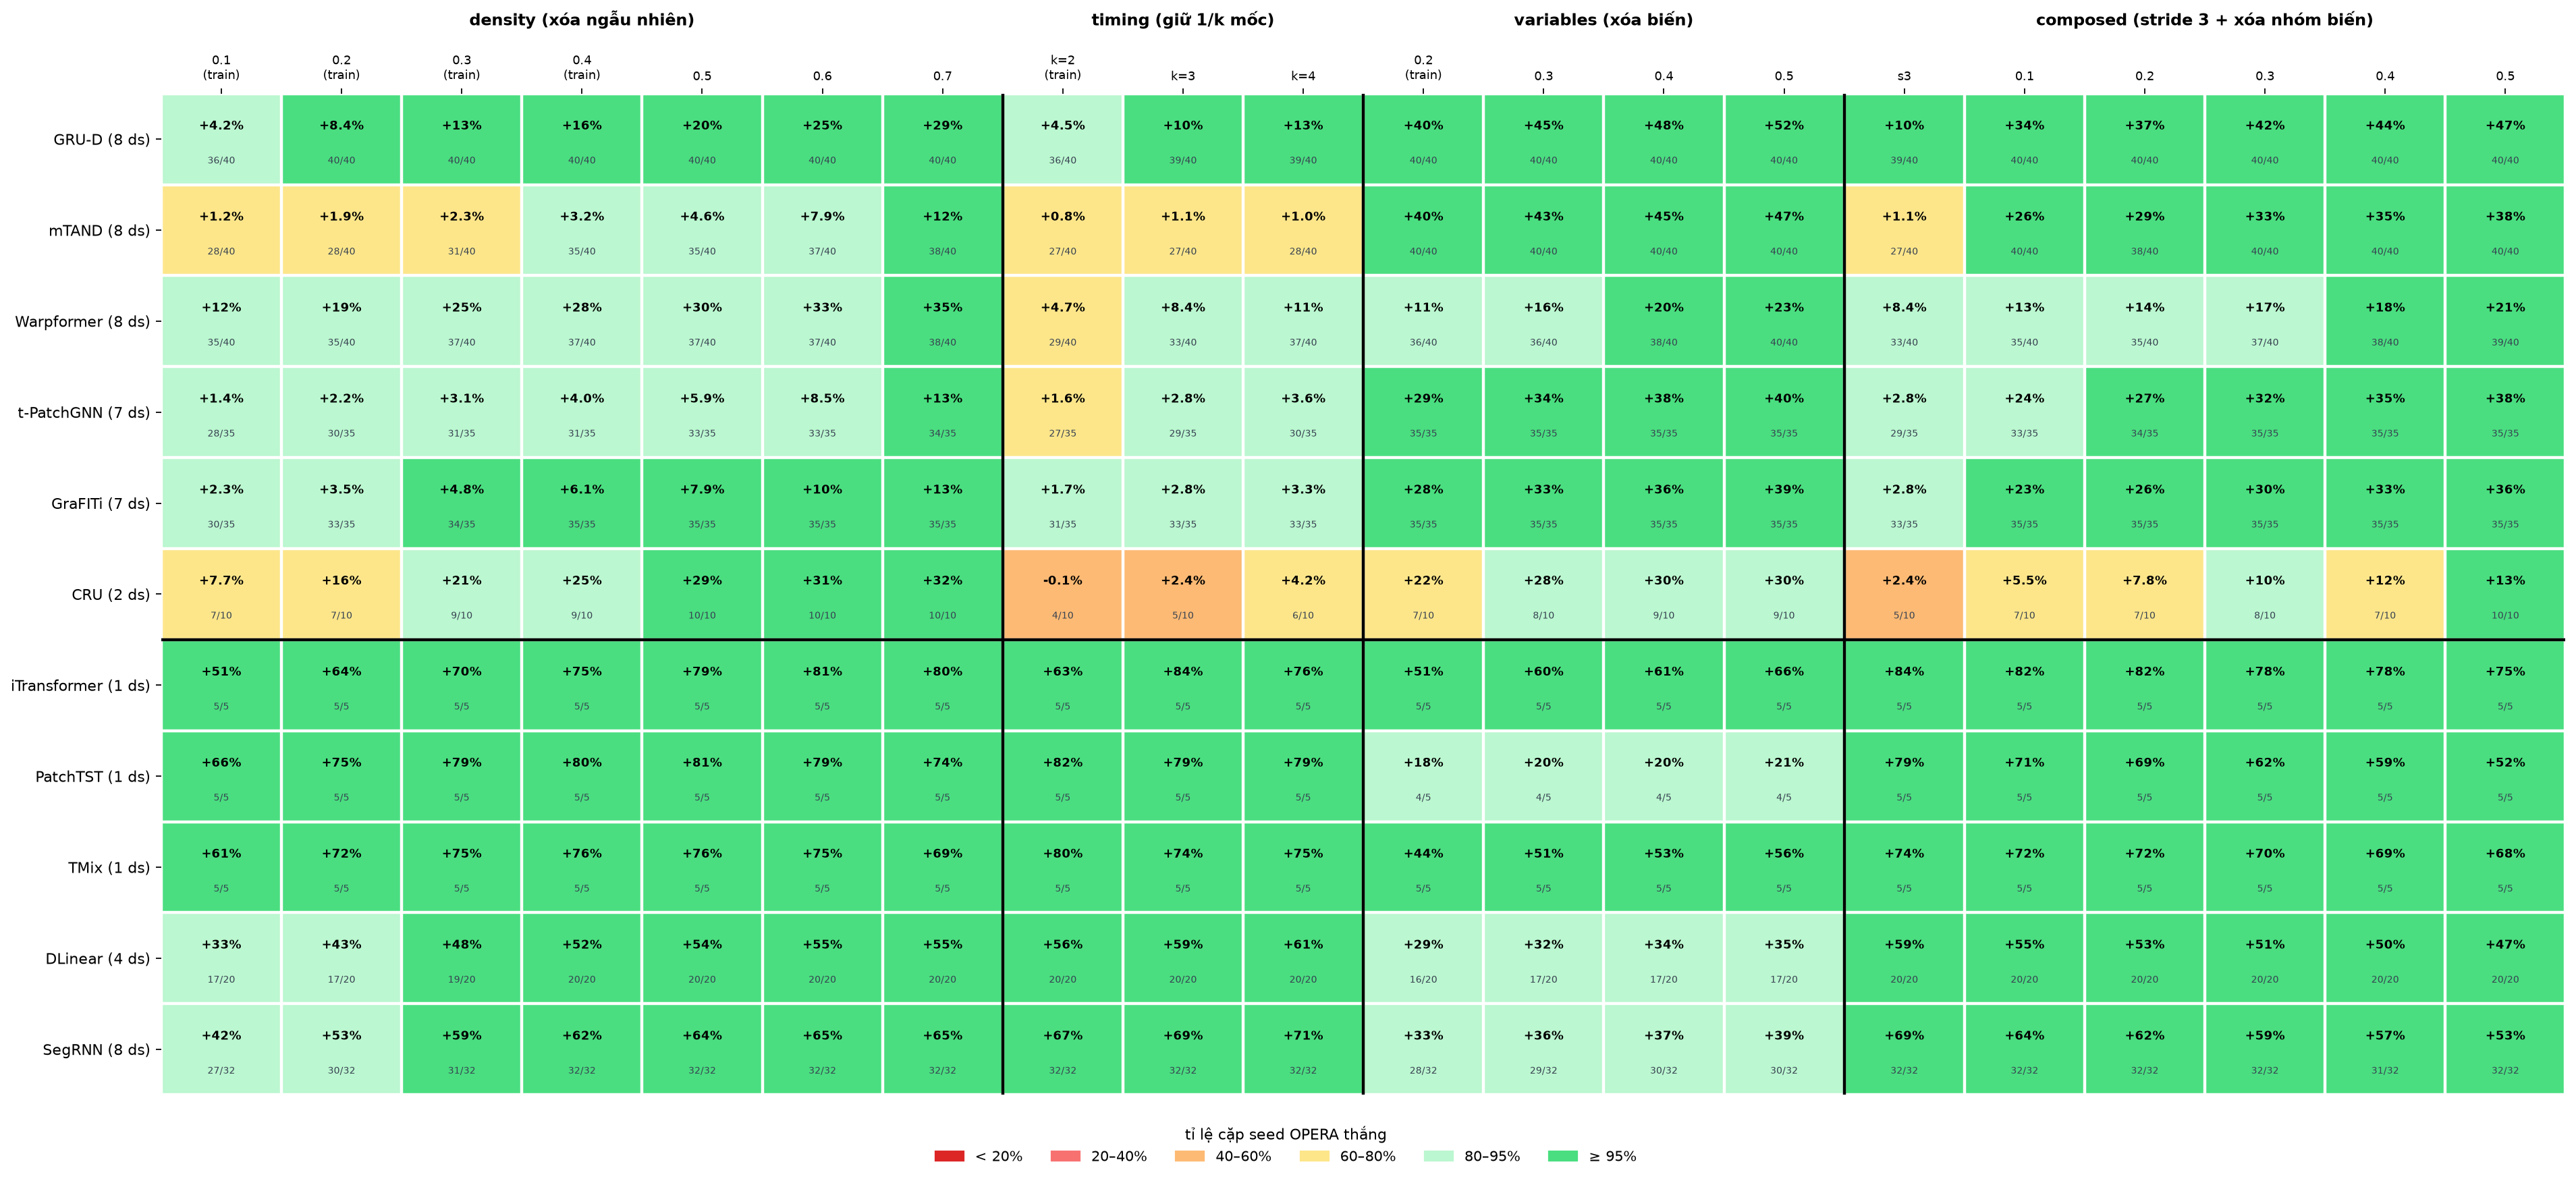

In [10]:
# (từ file 03 cũ, mở rộng cho 11 backbone) Thắng/thua theo từng mức shift: mỗi ô = backbone × loại shift × mức,
# gộp mọi dataset có sweep × seed. Màu = tỉ lệ cặp seed OPERA thắng; chữ = % OPERA hơn Vanilla (trung bình cặp) và số cặp thắng.
from matplotlib.colors import ListedColormap, BoundaryNorm
t = sp[~sp.clean & sp.family.ne('none')]
g = t.groupby(['backbone', 'family', 'severity']).agg(g=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size')).reset_index()
cols = [(f, v) for f in FAM for v in sorted(g[g.family.eq(f)].severity.unique())]
rows_ = [b for b in BB if b in set(g.backbone)]
wcmap = ListedColormap(['#dc2626', '#f87171', '#fdba74', '#fde68a', '#bbf7d0', '#4ade80'])
wnorm = BoundaryNorm([0, .2, .4, .6, .8, .95, 1.0001], 6)
G = g.set_index(['backbone', 'family', 'severity'])
M = np.array([[G.loc[(b, f, v), 'w'] / G.loc[(b, f, v), 'n'] for f, v in cols] for b in rows_])
fig, ax = plt.subplots(figsize=(24, 0.75 * len(rows_) + 2))
ax.imshow(M, cmap=wcmap, norm=wnorm, aspect='auto')
for i, b in enumerate(rows_):
    for j, (f, v) in enumerate(cols):
        r = G.loc[(b, f, v)]
        ax.text(j, i - .14, f'{r.g:+.0f}%' if abs(r.g) >= 9.5 else f'{r.g:+.1f}%', ha='center', va='center', fontsize=8, fontweight='bold')
        ax.text(j, i + .24, f'{int(r.w)}/{int(r.n)}', ha='center', va='center', fontsize=6.5, color='#374151')
lab = lambda f, v: ('s3' if (f == 'composed' and v == 0) else (f'k={v:g}' if f == 'temporal_stride' else f'{v:g}')) + ('\n(train)' if SEEN[f] is not None and v <= SEEN[f] else '')
ax.set_xticks(range(len(cols)), [lab(f, v) for f, v in cols], fontsize=8); ax.xaxis.tick_top()
ax.set_yticks(range(len(rows_)), [f'{BB[b]} ({cov.loc[b, "nds"]} ds)' for b in rows_], fontsize=10)
x0 = 0
for f in FAM:
    nf = sum(1 for c in cols if c[0] == f)
    ax.text(x0 + nf / 2 - .5, -1.25, FAM[f], ha='center', fontweight='bold', fontsize=11)
    if x0: ax.axvline(x0 - .5, color='black', lw=2)
    x0 += nf
ax.axhline(len(NATIVE) - .5 - sum(1 for b in NATIVE if b not in rows_), color='black', lw=2)
ax.set_xticks(np.arange(-.5, len(cols)), minor=True); ax.set_yticks(np.arange(-.5, len(rows_)), minor=True)
ax.grid(which='minor', color='white', lw=2); ax.tick_params(which='minor', length=0)
for q_ in ax.spines.values(): q_.set_visible(False)
h = [plt.Rectangle((0, 0), 1, 1, color=wcmap(i), label=l) for i, l in enumerate(['< 20%', '20–40%', '40–60%', '60–80%', '80–95%', '≥ 95%'])]
fig.legend(handles=h, title='tỉ lệ cặp seed OPERA thắng', loc='lower center', ncol=6, frameon=False, fontsize=9.5, bbox_to_anchor=(.5, -.06))
fig.tight_layout()
save(fig, 'tong_ket_fig2_1_win_by_level')


**Kết luận:** gộp mọi dataset có sweep, OPERA thắng **4989/5340** cặp seed (93%), và trong mỗi khối, ô càng về bên phải (mức càng nặng) càng xanh.
- **Xanh đậm gần như toàn bộ:** GRU-D, GraFITi, và cả 5 non-native (≥ 80% ở mọi ô; iTransformer / TMix 5/5 ở mọi ô, nhưng chỉ 1 dataset). **Variables** xanh ở mọi native trừ CRU.
- **Chỗ không ổn định:** mTAND ở density 0.1–0.3 và **mọi mức timing** (27–31/40 cặp, chênh chỉ +0.8% đến +2.3%); timing k = 2 ở Warpformer (29/40) và t-PatchGNN (27/35); **CRU** (2 dataset) ở timing và composed nhẹ (4–7/10, có ô −0.1%).
- **Non-native · variables** là chỗ duy nhất ở nhóm này không đạt 95% (PatchTST 4/5, DLinear 16–17/20, SegRNN 28–30/32), dù OPERA vẫn hơn trung bình +18% đến +39%.

<a id="hinh-2-2"></a>

#### 📈 Hình 2.2 · Đường cong tổng quan: native và non-native

- Hai hàng = hai nhóm backbone; mỗi hàng gộp mọi ô dataset × backbone có sweep trong nhóm (số ô ghi ở nhãn hàng). Bảng dưới: ở sạch và ở mức nặng nhất.

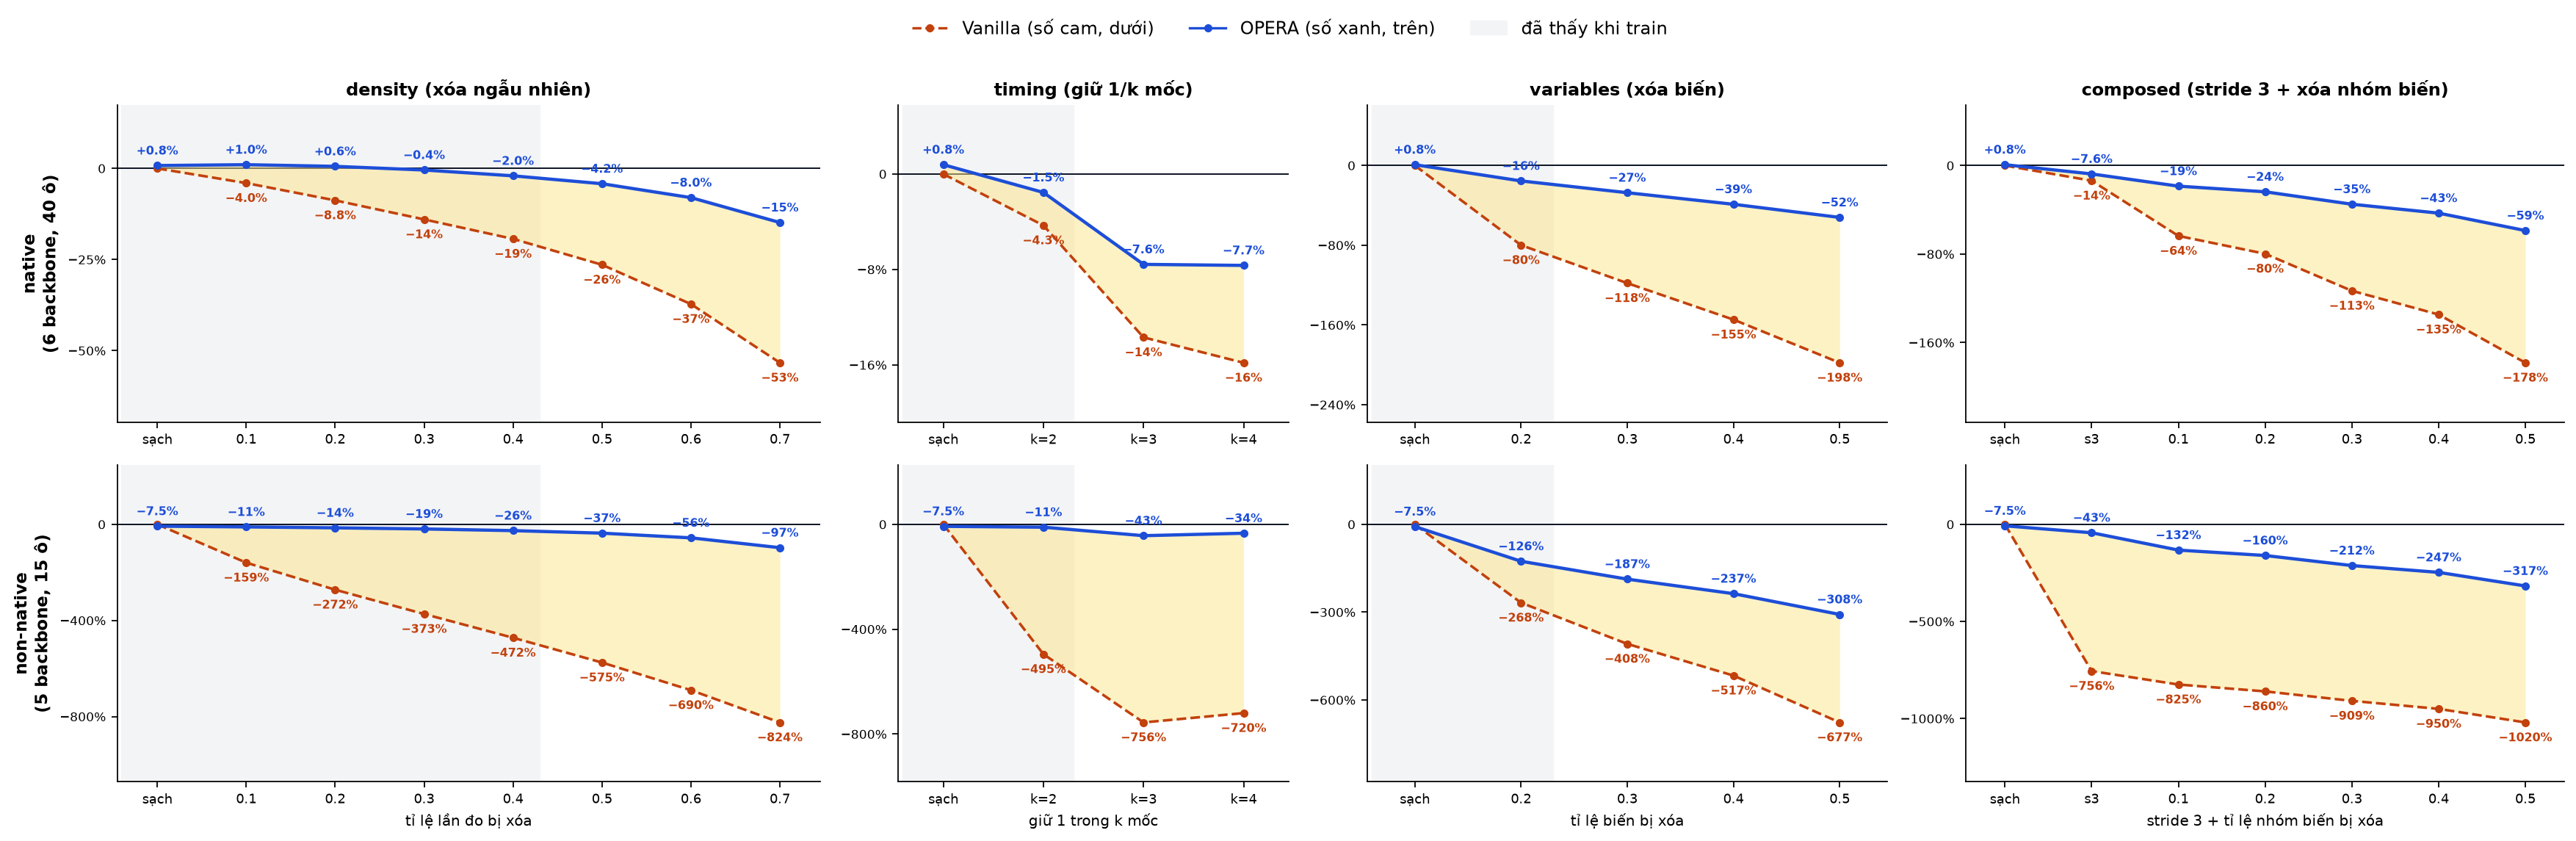

clean: OPERA  nặng nhất: Vanilla  nặng nhất: OPERA
nhóm       loại shift                                                    
native     density              0.8               -53.3             -14.8
           timing               0.8               -15.8              -7.7
           variables            0.8              -197.9             -52.1
           composed             0.8              -178.2             -58.7
non-native density             -7.5              -824.5             -97.1
           timing              -7.5              -720.0             -33.8
           variables           -7.5              -676.6            -307.6
           composed            -7.5             -1020.0            -317.1

In [11]:
# Hình 2.1: hai hàng = native / non-native, mỗi hàng gộp mọi ô dataset × backbone có sweep trong nhóm đó.
g21 = []
for fam_bb in ['native', 'non-native']:
    d = cm_[cm_.family_bb.eq(fam_bb)]
    nb = d.backbone.nunique(); nc = d[['dataset', 'backbone']].drop_duplicates().shape[0]
    g21.append((f'{fam_bb}\n({nb} backbone, {nc} ô)', d))
t21 = curve_grid(g21, 'tong_ket_fig2_2_overview_by_family', row_h=3.6)
display(t21.set_index(['nhóm', 'loại shift']).round(1))


**Kết luận:** cả hai nhóm có cùng hình dạng: Vanilla (cam) đi xuống theo mức nặng, OPERA (xanh) đi xuống chậm hơn nhiều, vùng vàng rộng dần. Khác nhau ở **độ lớn**:
- **Native (6 backbone, 40 ô):** clean +0.8%. OPERA còn trên hoặc sát 0 tới density 0.3. Mức nặng nhất: density −53% → −15%, timing −16% → −7.7%, variables −198% → −52%, composed −178% → −59%.
- **Non-native (5 backbone, 15 ô):** clean **−7.5%** (OPERA bắt đầu dưới Vanilla), nhưng Vanilla sụp ngay từ mức nhẹ nhất (density 0.1: −159%, timing k = 2: −495%). OPERA gần như phẳng ở density (−97% ở 0.7) và timing (−34% ở k = 4). Variables và composed thì OPERA vẫn tụt nhiều (−308%, −317%) nhưng vẫn ít hơn Vanilla 2–3 lần.

Hàng non-native chỉ có 15 ô (DLinear 4, SegRNN 8, iTransformer / PatchTST / TMix mỗi cái 1 ô CGMacros), nên số gộp bị SegRNN chi phối.

<a id="hinh-2-3"></a>

#### 📈 Hình 2.3 · Đường cong theo từng backbone

- Mỗi hàng = một backbone, gộp các dataset có sweep của backbone đó (số dataset ghi ở nhãn hàng). **iTransformer / PatchTST / TMix chỉ có sweep ở CGMacros**, nên hàng của chúng là 1 dataset.

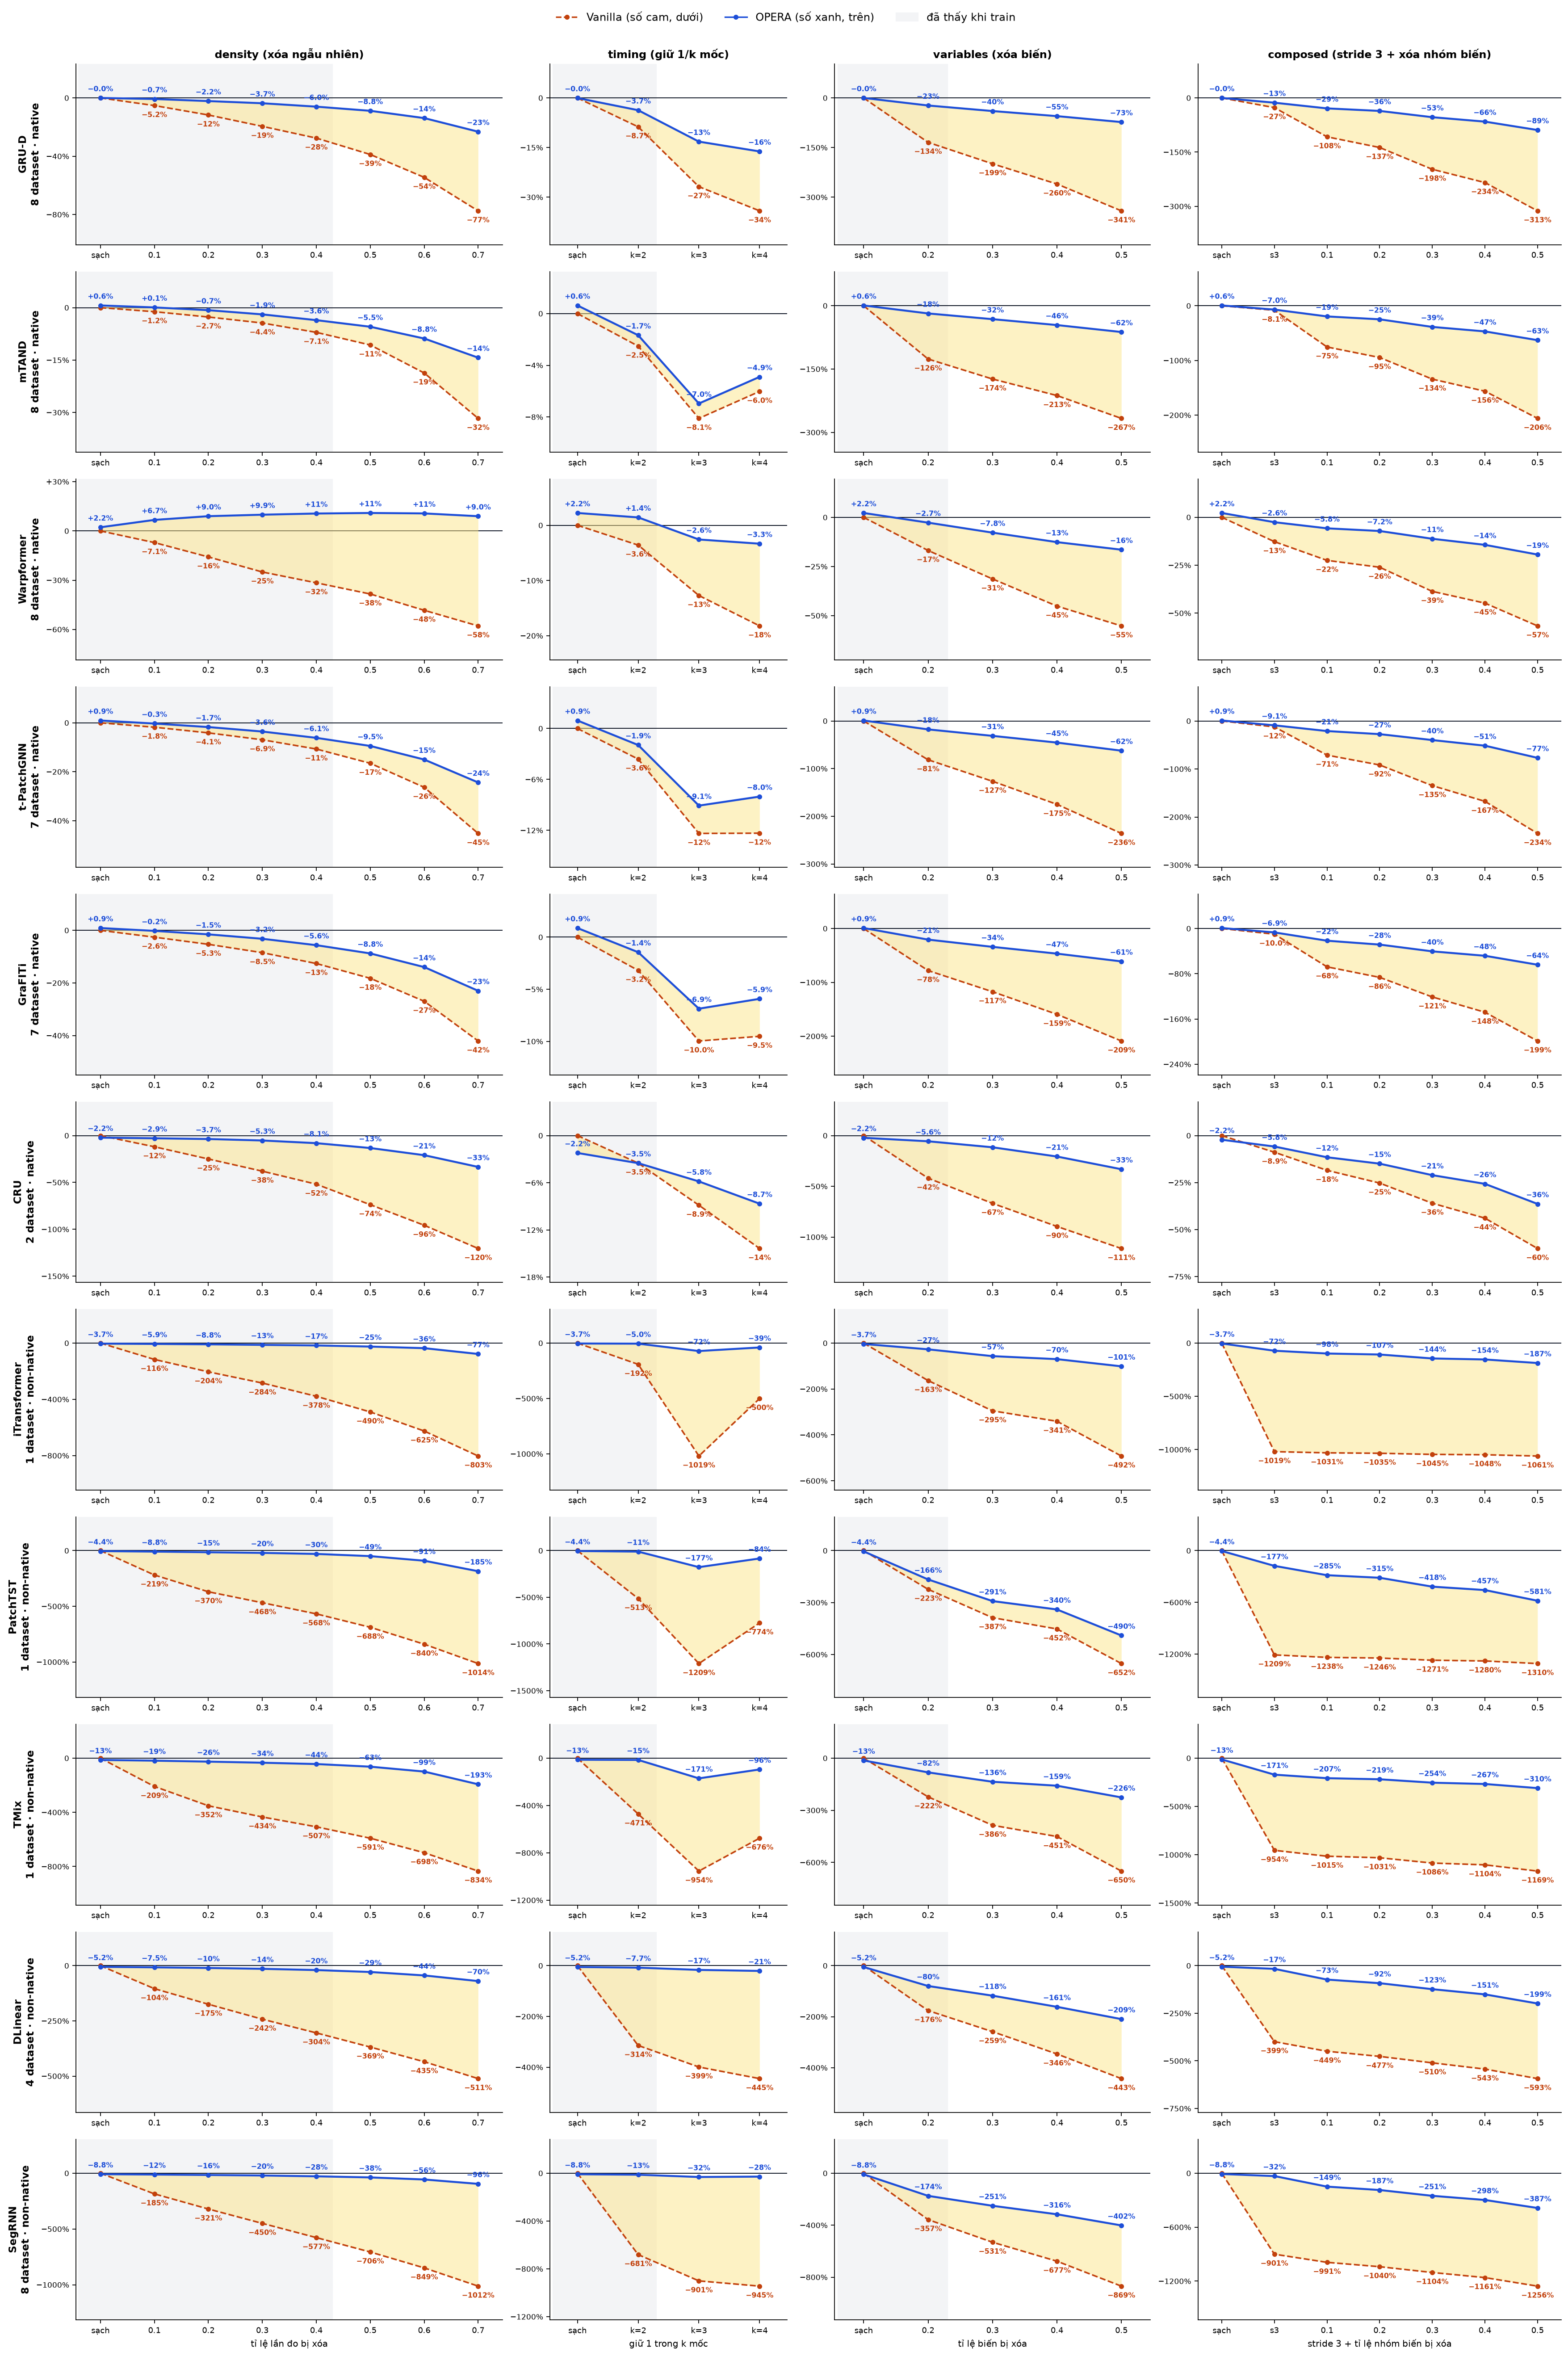

clean: OPERA                          nặng nhất: Vanilla                          nặng nhất: OPERA                         
loại shift       composed density timing variables           composed density timing variables         composed density timing variables
nhóm                                                                                                                                    
CRU                  -2.2    -2.2   -2.2      -2.2              -60.1  -120.5  -14.4    -111.3            -36.3   -33.5   -8.7     -33.2
DLinear              -5.2    -5.2   -5.2      -5.2             -593.1  -511.5 -444.9    -442.7           -198.6   -69.7  -20.7    -209.4
GRU-D                -0.0    -0.0   -0.0      -0.0             -312.5   -77.5  -34.1    -341.2            -88.9   -23.2  -16.2     -73.0
GraFITi               0.9     0.9    0.9       0.9             -198.8   -42.1   -9.5    -208.8            -64.0   -23.0   -5.9     -61.1
PatchTST             -4.4    -4.4   -4.4      -4.4            -1309.7 -1014.2 -774.4    -652.1           -581.2  -185.0  -84.1    -490.0
SegRNN               -8.8    -8.8   -8.8      -8.8            -1256.0 -1012.3 -944.7    -869.1           -386.8   -95.5  -28.5    -401.8
TMix                -13.3   -13.3  -13.3     -13.3            -1168.7  -833.7 -675.8    -649.6           -310.0  -193.0  -95.5    -225.7
Warpformer            2.2     2.2    2.2       2.2              -56.6   -57.9  -18.2     -55.2            -19.4     9.0   -3.3     -16.4
iTransformer         -3.7    -3.7   -3.7      -3.7            -1060.6  -803.0 -500.3    -492.0           -187.2   -77.4  -39.5    -101.3
mTAND                 0.6     0.6    0.6       0.6             -206.0   -31.7   -6.0    -266.8            -62.9   -14.3   -4.9     -62.3
t-PatchGNN            0.9     0.9    0.9       0.9             -234.3   -45.2  -12.3    -236.0            -76.8   -24.4   -8.0     -62.3

In [12]:
# Hình 2.2: mỗi hàng = một backbone (gộp các dataset có sweep của backbone đó).
g22 = []
for b in BB:
    d = cm_[cm_.backbone.eq(b)]
    if len(d):
        g22.append((f'{BB[b]}\n{cov.loc[b, "nds"]} dataset · {"native" if b in NATIVE else "non-native"}', d))
t22 = curve_grid(g22, 'tong_ket_fig2_3_by_backbone', row_h=3.0)
display(t22.set_index(['nhóm', 'loại shift']).round(1).unstack('loại shift'))


**Kết luận:** ở mức nặng nhất, OPERA tụt ít hơn Vanilla ở **44/44** ô (11 backbone × 4 loại shift).

| Nhóm | Backbone | Hình dạng | Số đáng chú ý (mức nặng nhất, Vanilla → OPERA) |
|---|---|---|---|
| native | GRU-D, mTAND, t-PatchGNN, GraFITi | Giống nhau: clean ≈ 0, hai đường tách dần, mất biến là nặng nhất | variables: GRU-D −341% → −73%, t-PatchGNN −236% → −62%, GraFITi −209% → −61%. mTAND · timing gần như không có khoảng cách (−6.0% → −4.9%) |
| native | Warpformer | Density OPERA **trên 0 suốt** (tới +11%) | Chỗ lạ đã ghi ở [Bảng 2.7](#bang-2-7), chưa giải thích; không dùng làm bằng chứng |
| native | CRU (2 dataset) | Clean −2.2%; timing k = 2 OPERA kém hơn Vanilla, từ k = 3 mới vượt | density −120% → −33%, variables −111% → −33% |
| non-native | iTransformer, PatchTST, TMix (chỉ CGMacros) | Clean dưới 0 (−3.7% đến −13%), Vanilla sụp hàng trăm % ngay mức nhẹ, OPERA gần phẳng ở density / timing | density: iTransformer −803% → −77%, PatchTST −1014% → −185%. Timing k = 3 tệ hơn k = 4 ở cả hai model (đặc thù CGMacros, đã thấy ở 03) |
| non-native | DLinear (4 dataset), SegRNN (8 dataset) | Như trên, dataset nhiều hơn nên chắc hơn | SegRNN: density −1012% → −96%, timing −945% → −28%, variables −869% → −402%. DLinear: density −511% → −70% |

Với report: GRU-D (native) và SegRNN (non-native) là hai ví dụ đủ dataset và rõ nhất cho hai nhóm.

<a id="hinh-2-4"></a>

#### 📈 Hình 2.4 · Đường cong theo từng dataset (native backbone)

- Mỗi hàng = một dataset, gộp các **native** backbone có ở dataset đó (không gộp non-native vì mức sụp của hai nhóm khác nhau hàng chục lần).

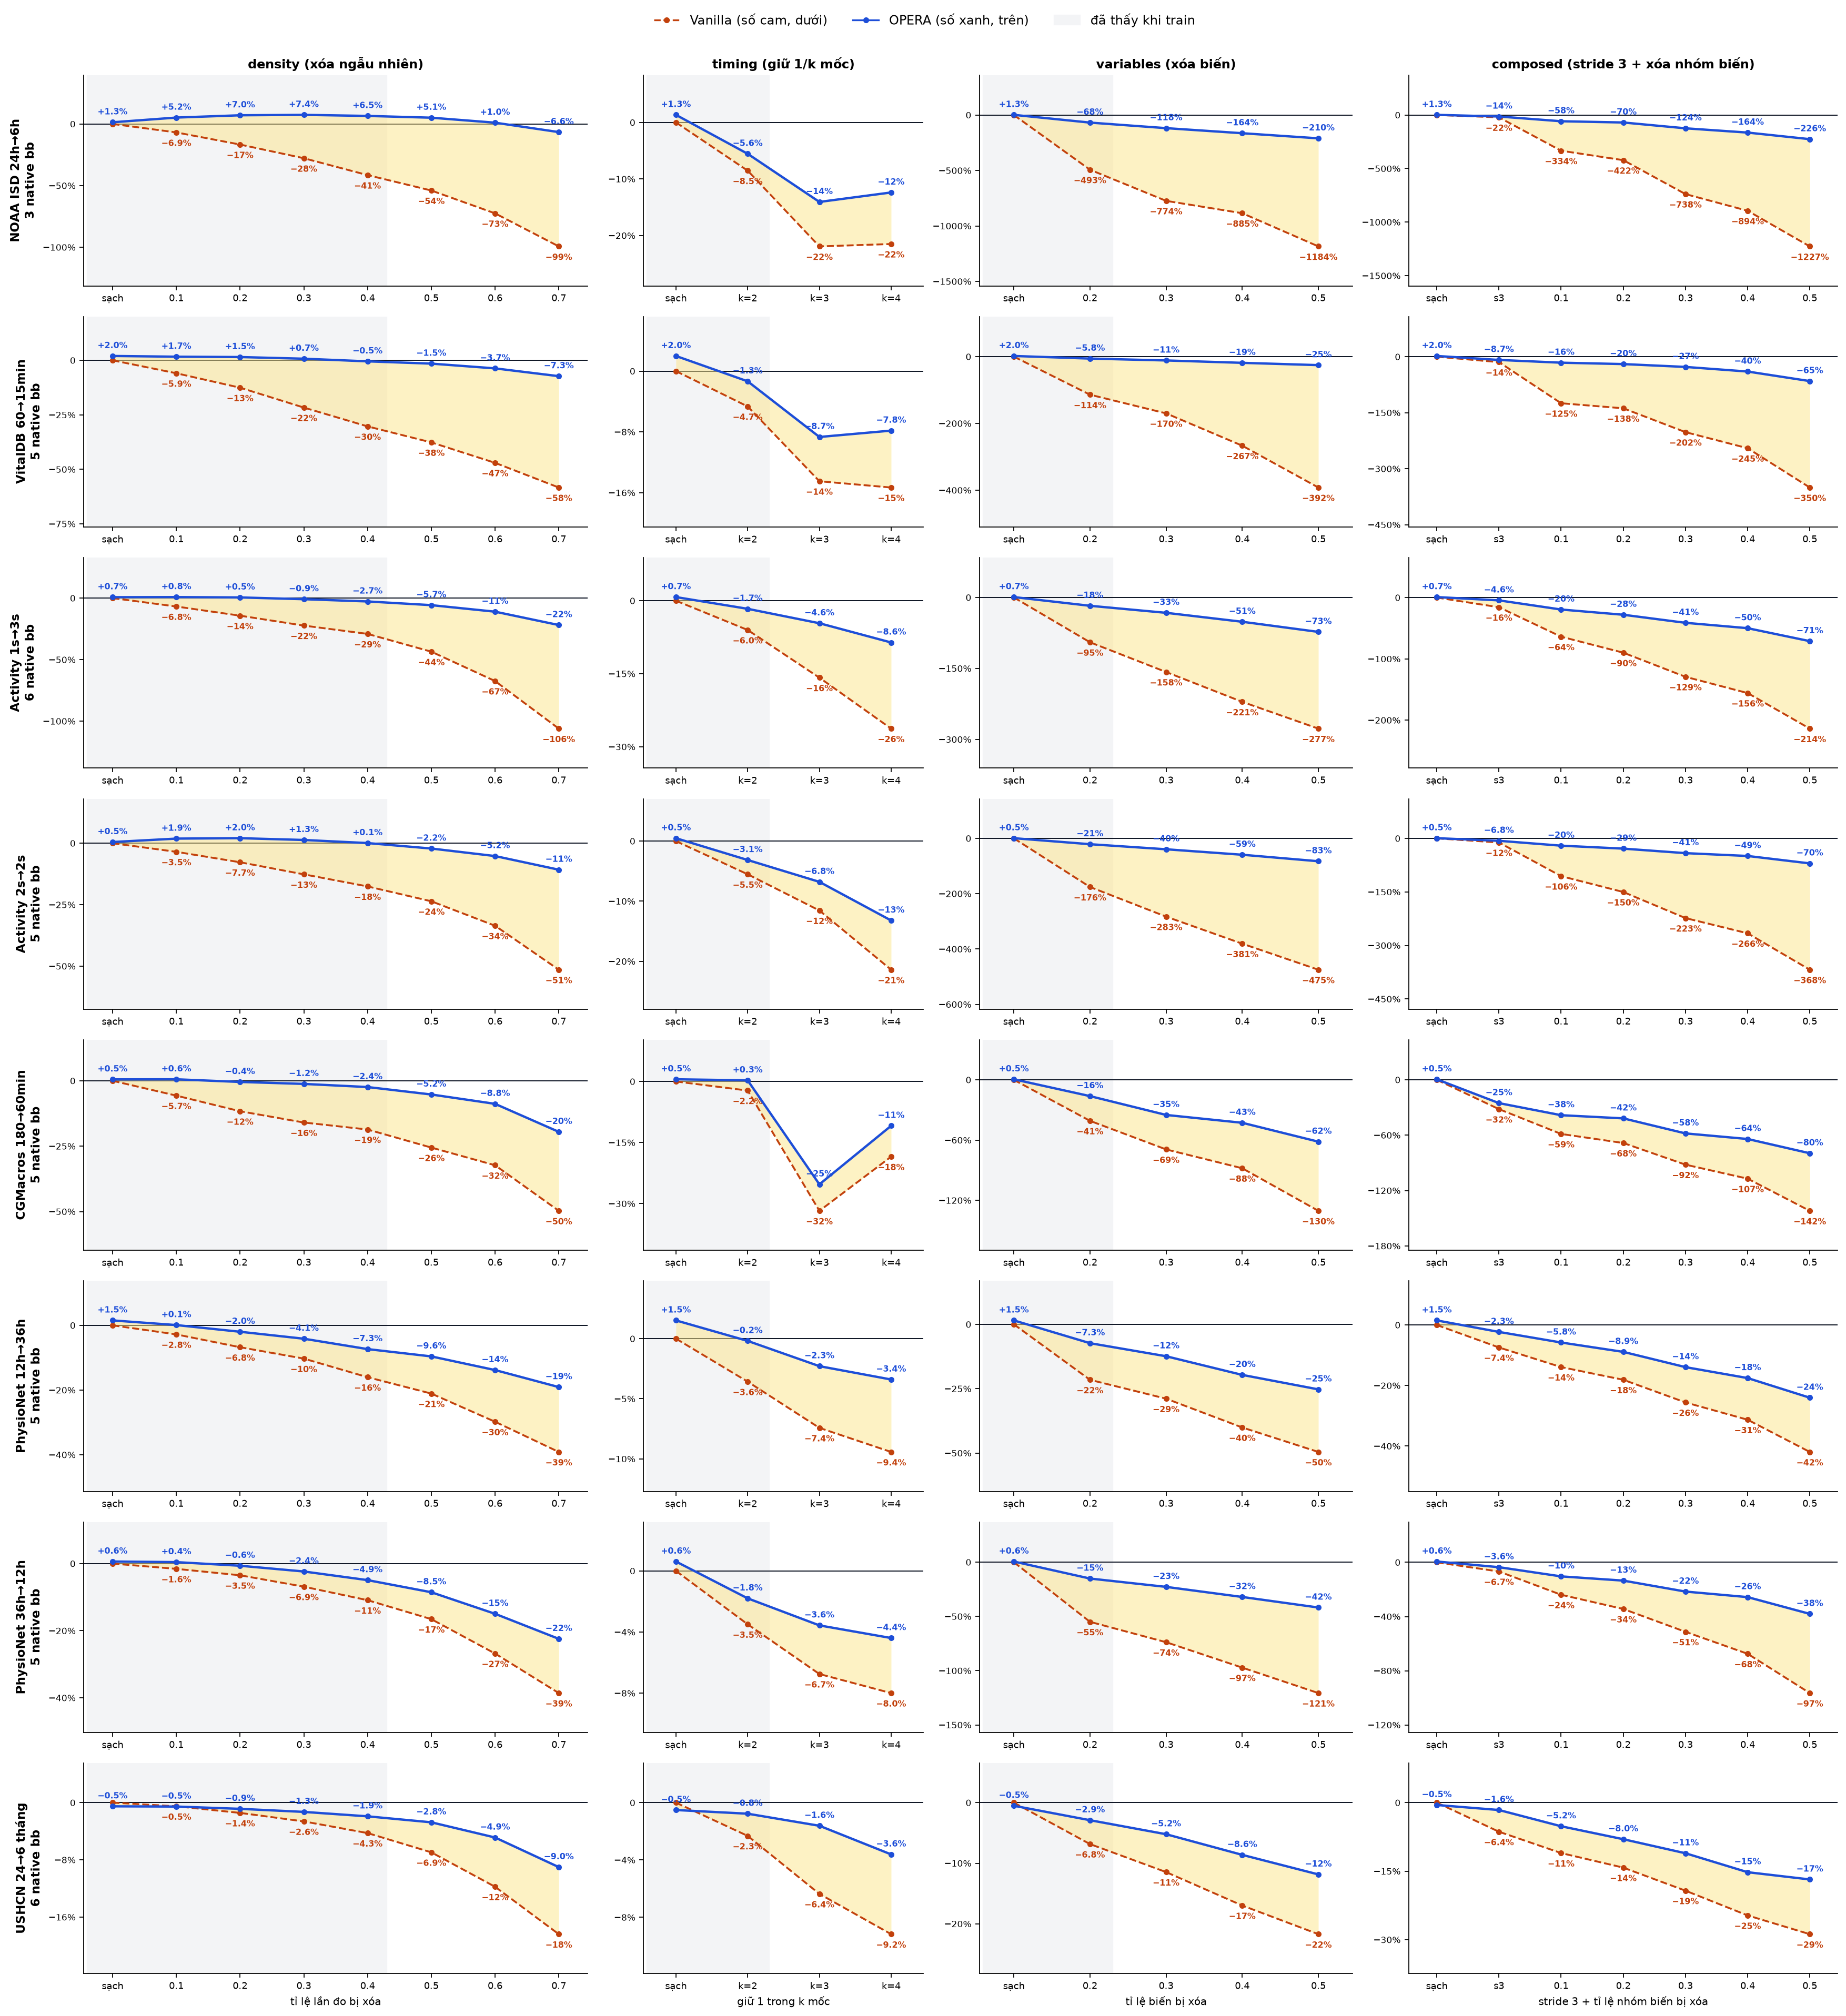

clean: OPERA                          nặng nhất: Vanilla                          nặng nhất: OPERA                         
loại shift             composed density timing variables           composed density timing variables         composed density timing variables
nhóm                                                                                                                                          
Activity 1s→3s              0.7     0.7    0.7       0.7             -213.8  -106.1  -26.3    -277.3            -71.1   -21.9   -8.6     -72.8
Activity 2s→2s              0.5     0.5    0.5       0.5             -368.1   -51.5  -21.4    -474.9            -70.1   -10.8  -13.2     -82.8
CGMacros 180→60min          0.5     0.5    0.5       0.5             -142.0   -49.7  -18.5    -130.5            -79.6   -19.5  -10.9     -61.6
NOAA ISD 24h→6h             1.3     1.3    1.3       1.3            -1226.8   -99.3  -21.5   -1184.5           -225.5    -6.6  -12.4    -210.4
PhysioNet 12h→36h           1.5     1.5    1.5       1.5              -42.0   -39.1   -9.4     -49.6            -24.0   -19.1   -3.4     -25.3
PhysioNet 36h→12h           0.6     0.6    0.6       0.6              -96.5   -38.6   -8.0    -120.7            -38.0   -22.4   -4.4     -41.8
USHCN 24→6 tháng           -0.5    -0.5   -0.5      -0.5              -28.8   -18.4   -9.2     -21.7            -16.8    -9.0   -3.6     -11.9
VitalDB 60→15min            2.0     2.0    2.0       2.0             -350.4   -58.3  -15.3    -392.0            -65.3    -7.3   -7.8     -25.4

In [13]:
# (từ file 03 cũ) Đường cong theo từng dataset, chỉ gộp các NATIVE backbone có ở dataset đó (gộp native với non-native sẽ lẫn hai mức sụp rất khác nhau).
g24 = []
for s in DS:
    d = cm_[cm_.dataset.eq(s) & cm_.family_bb.eq('native')]
    g24.append((f'{NAME[s]}\n{d.backbone.nunique()} native bb', d))
t24 = curve_grid(g24, 'tong_ket_fig2_4_by_dataset_native', row_h=3.0)
display(t24.set_index(['nhóm', 'loại shift']).round(1).unstack('loại shift'))


**Kết luận:** ở mức nặng nhất, OPERA tụt ít hơn Vanilla ở **32/32** ô (8 dataset × 4 loại shift, gộp native). Khoảng cách theo dataset đi theo mức Vanilla sụp:
- **Sụp mạnh nhất khi mất biến:** NOAA (variables 0.5: −1184% → −210%), Activity 2s (−475% → −83%), VitalDB (−392% → −25%), Activity 1s (−277% → −73%).
- **Density 0.7:** NOAA −99% → −6.6%, VitalDB −58% → −7.3%, Activity 2s −52% → −11%.
- **Hẹp nhất:** USHCN (variables −22% → −12%, density −18% → −9%) và timing ở mọi dataset (Vanilla chỉ −8% đến −26%).
- Clean: OPERA từ −0.5% (USHCN) đến +2.0% (VitalDB) so với Vanilla, nên không dataset nào Vanilla native tốt hơn rõ lúc đầu.

<a id="bang-2-5"></a>

#### 📋 Bảng 2.5 · OPERA thua ở đâu: đếm cặp thua và 10 cặp thua nặng nhất

- Bảng trên: số cặp thua / số cặp, theo backbone × loại shift (không tính clean). Bảng dưới: 10 cặp có % OPERA hơn thấp nhất, kèm kết quả **clean ở cùng seed** và cờ Vanilla seed đó bị NaN.

In [14]:
# (từ file 03 cũ, mở rộng) Đếm cặp seed thua theo backbone × loại shift (không tính clean), và 10 cặp thua nặng nhất.
t = sp[~sp.clean].drop_duplicates(['dataset', 'backbone', 'seed', 'family', 'severity'])
cnt = t.groupby(['backbone', 'family']).apply(lambda d: f'{(~d.win).sum()}/{len(d)}', include_groups=False).unstack()
cnt['tổng'] = t.groupby('backbone').apply(lambda d: f'{(~d.win).sum()}/{len(d)} ({100 * (~d.win).mean():.0f}%)', include_groups=False)
cnt = cnt.reindex([b for b in BB if b in cnt.index])
cnt.loc['tổng native'] = [f'{(~t[t.family.eq(f) & t.backbone.isin(list(NATIVE))].win).sum()}/{(t.family.eq(f) & t.backbone.isin(list(NATIVE))).sum()}' for f in cnt.columns[:-1]] + [f'{(~t[t.backbone.isin(list(NATIVE))].win).sum()}/{t.backbone.isin(list(NATIVE)).sum()}']
cnt.loc['tổng non-native'] = [f'{(~t[t.family.eq(f) & ~t.backbone.isin(list(NATIVE))].win).sum()}/{(t.family.eq(f) & ~t.backbone.isin(list(NATIVE))).sum()}' for f in cnt.columns[:-1]] + [f'{(~t[~t.backbone.isin(list(NATIVE))].win).sum()}/{(~t.backbone.isin(list(NATIVE))).sum()}']
display(cnt.rename(index=BB, columns=lambda f: FAM.get(f, f).split(' (')[0]))
lo = t[~t.win]
cg = sp[sp.clean & sp.family.eq('random_dropout')].set_index(['dataset', 'backbone', 'seed']).gain
lo2 = lo.join(cg.rename('g_clean'), on=['dataset', 'backbone', 'seed'])
print(f'Cặp thua: {len(lo)}/{len(t)} · trung vị {lo.gain.median():.2f}% · nặng nhất {lo.gain.min():.1f}% · '
      f'{(lo2.g_clean < 0).sum()} cặp ({100 * (lo2.g_clean < 0).mean():.0f}%) thuộc seed mà OPERA đã thua sẵn khi clean')
worst = lo2.nsmallest(10, 'gain')
display(pd.DataFrame({'dataset': worst.dataset.map(NAME), 'backbone': worst.backbone.map(BB), 'seed': worst.seed,
                      'loại shift': worst.family.map(lambda f: FAM[f].split(' (')[0]), 'mức': worst.severity,
                      'OPERA hơn (%)': worst.gain.round(1), 'clean cùng seed: OPERA hơn (%)': worst.g_clean.round(1),
                      'Vanilla seed này NaN': [((nanrun.dataset == r.dataset) & (nanrun.backbone == r.backbone) & (nanrun.seed == r.seed)).any() for r in worst.itertuples()]}).reset_index(drop=True))


family,composed,density,timing,variables,tổng
backbone,,,,,
GRU-D,1/240,4/280,6/120,0/160,11/800 (1%)
mTAND,15/240,48/280,38/120,0/160,101/800 (13%)
Warpformer,23/240,24/280,21/120,10/160,78/800 (10%)
t-PatchGNN,9/210,25/245,19/105,0/140,53/700 (8%)
GraFITi,2/210,8/245,8/105,0/140,18/700 (3%)
CRU,16/60,8/70,15/30,7/40,46/200 (23%)
iTransformer,0/30,0/35,0/15,0/20,0/100 (0%)
PatchTST,0/30,0/35,0/15,4/20,4/100 (4%)
TMix,0/30,0/35,0/15,0/20,0/100 (0%)


Cặp thua: 351/5340 · trung vị -0.89% · nặng nhất -16.1% · 336 cặp (96%) thuộc seed mà OPERA đã thua sẵn khi clean


,dataset,backbone,seed,loại shift,mức,OPERA hơn (%),clean cùng seed: OPERA hơn (%),Vanilla seed này NaN
0,PhysioNet 36h→12h,Warpformer,4,density,0.2,-16.1,-15.5,False
1,PhysioNet 36h→12h,Warpformer,4,density,0.1,-14.3,-15.5,False
2,NOAA ISD 24h→6h,mTAND,1,density,0.1,-13.7,-14.1,False
3,USHCN 24→6 tháng,t-PatchGNN,0,density,0.1,-13.6,-14.1,False
4,USHCN 24→6 tháng,t-PatchGNN,0,density,0.2,-13.3,-14.1,False
5,NOAA ISD 24h→6h,mTAND,1,density,0.2,-13.2,-14.1,False
6,PhysioNet 36h→12h,Warpformer,4,density,0.3,-13.0,-15.5,False
7,NOAA ISD 24h→6h,mTAND,1,density,0.3,-12.9,-14.1,False
8,USHCN 24→6 tháng,t-PatchGNN,0,timing,2.0,-12.8,-14.1,False
9,USHCN 24→6 tháng,t-PatchGNN,0,composed,0.0,-12.6,-14.1,False


**Kết luận:** 351/5340 cặp thua (7%). Phần lớn ở native (307/4000): mTAND 101, Warpformer 78, t-PatchGNN 53, CRU 46/200 (23%); GRU-D chỉ 11/800, GraFITi 18/700. Non-native chỉ 44/1340, chủ yếu **variables** (28/268). Theo loại shift ở native: timing thua nhiều nhất (107/600, 18%), variables ít nhất (17/800).
- Cặp thua thường thua rất ít: trung vị −0.89%.
- **96% cặp thua thuộc seed mà OPERA đã thua sẵn khi clean.** 10 cặp thua nặng nhất chỉ thuộc 3 seed (PhysioNet 36h · Warpformer · s4, NOAA · mTAND · s1, USHCN · t-PatchGNN · s0), cả ba đã thua 14–16% ngay ở clean. Shift không tạo ra chỗ thua mới; nó chỉ chưa đủ mạnh để lấp phần thua có sẵn từ clean, nhất là ở mức nhẹ.

<a id="bang-2-6"></a>

#### 📋 Bảng 2.6 · Trong và ngoài vùng đã train

- **Mốc** = mức nặng nhất có trong mixture train (density 0.4, k = 2, variables 0.2; composed: stride 3 đơn thuần vì chưa thấy mức nào). **Nặng nhất** = mức nặng nhất được test. Mỗi ô: % OPERA hơn Vanilla (trung bình cặp) và (cặp thắng / số cặp), tách native / non-native.

In [15]:
# (từ file 03 cũ, mở rộng) Trong vs ngoài vùng đã train: mức nặng nhất OPERA đã thấy (mốc) so với mức nặng nhất được test.
rows = []
for fam in FAM:
    hi = sp[sp.family.eq(fam)].severity.max()
    lo_ = SEEN[fam] if SEEN[fam] is not None else 0.0     # composed: chưa thấy mức nào; mốc = stride 3 đơn thuần
    for fb in ['native', 'non-native']:
        q_ = sp[sp.family.eq(fam) & sp.family_bb.eq(fb)]
        a_, b_ = q_[q_.severity.eq(lo_)], q_[q_.severity.eq(hi)]
        rows.append({'loại shift': FAM[fam].split(' (')[0], 'nhóm': fb, 'mốc': f'{lo_:g}' if fam != 'composed' else 's3',
                     'OPERA hơn ở mốc': f'{mark(a_.win.sum(), len(a_))} {a_.gain.mean():+.1f}% ({a_.win.sum()}/{len(a_)})',
                     'nặng nhất': f'{hi:g}',
                     'OPERA hơn ở mức nặng nhất': f'{mark(b_.win.sum(), len(b_))} {b_.gain.mean():+.1f}% ({b_.win.sum()}/{len(b_)})',
                     'backbone có cặp thua ở mức nặng nhất': ', '.join(sorted({BB[x] for x in b_[~b_.win].backbone}))})
display(pd.DataFrame(rows).set_index(['loại shift', 'nhóm']))
t = sp[~sp.clean].drop_duplicates(['dataset', 'backbone', 'seed', 'family', 'severity'])
for fb in ['native', 'non-native']:
    u = t[t.family_bb.eq(fb)]
    print(f'{fb}: vùng đã thấy khi train {u[u.seen].win.sum()}/{u.seen.sum()} ({100 * u[u.seen].win.mean():.0f}%) · '
          f'vùng chưa thấy {u[~u.seen].win.sum()}/{(~u.seen).sum()} ({100 * u[~u.seen].win.mean():.0f}%)')


mốc     OPERA hơn ở mốc nặng nhất OPERA hơn ở mức nặng nhất               backbone có cặp thua ở mức nặng nhất
loại shift nhóm                                                                                                                      
density    native      0.4  🟢 +12.4% (187/200)       0.7        🟢 +21.5% (195/200)                      Warpformer, mTAND, t-PatchGNN
           non-native  0.4    🟢 +62.5% (67/67)       0.7          🟢 +64.0% (67/67)                                                   
timing     native        2   ⚪ +2.6% (154/200)         4         🟢 +6.5% (173/200)  CRU, GRU-D, GraFITi, Warpformer, mTAND, t-Patc...
           non-native    2    🟢 +65.4% (67/67)         4          🟢 +69.0% (67/67)                                                   
variables  native      0.2  🟢 +29.5% (193/200)       0.5        🟢 +39.7% (199/200)                                                CRU
           non-native  0.2    🟢 +32.8% (58/67)       0.5          🟢 +39.5% (61/67)                          DLinear, PatchTST, SegRNN
composed   native       s3   🟢 +5.1% (166/200)       0.5        🟢 +35.0% (199/200)                                         Warpformer
           non-native   s3    🟢 +68.5% (67/67)       0.5          🟢 +53.8% (67/67)

native: vùng đã thấy khi train 1053/1200 (88%) · vùng chưa thấy 2640/2800 (94%)
non-native: vùng đã thấy khi train 378/402 (94%) · vùng chưa thấy 918/938 (98%)


**Kết luận:** ra khỏi vùng đã train, OPERA thắng **nhiều hơn** chứ không ít đi: native 88% → 94% cặp, non-native 94% → 98%. Ở native, các ô ⚪ đều ở mốc nhẹ (timing k = 2: +2.6%, 154/200); ở mức nặng nhất thì mọi ô 🟢. Ở non-native, chỉ variables còn vài cặp thua ở mức nặng nhất (DLinear, PatchTST, SegRNN; 61/67 thắng).

<a id="bang-2-7"></a>

#### 📋 Bảng 2.7 · Chỗ lạ: MSE khi shift thấp hơn MSE sạch

- Các ô (dataset × backbone × loại shift × mức) có MSE ÷ MSE sạch < 0.97 (trung bình seed), ở Vanilla hoặc OPERA. Bên dưới: MSE từng seed của NOAA · Warpformer · OPERA theo mức xóa.

In [16]:
# (từ file 03 cũ, mở rộng) Chỗ lạ: MSE khi bị shift THẤP hơn MSE sạch của chính model đó (tỉ số < 0.97, trung bình seed).
odd = sp[~sp.clean].groupby(['dataset', 'backbone', 'family', 'severity'])[['r_v', 'r_o']].mean()
odd = odd[(odd.r_v < 0.97) | (odd.r_o < 0.97)].round(3).reset_index()
print('Số ô lạ theo backbone × phương pháp:',
      {f'{BB[b]} · {"OPERA" if c == "r_o" else "Vanilla"}': int((odd[odd.backbone.eq(b)][c] < .97).sum()) for b in odd.backbone.unique() for c in ['r_v', 'r_o'] if (odd[odd.backbone.eq(b)][c] < .97).any()})
odd['dataset'] = odd.dataset.map(NAME); odd['backbone'] = odd.backbone.map(BB); odd['family'] = odd.family.map(lambda f: FAM[f].split(' (')[0])
display(odd.rename(columns={'r_v': 'Vanilla: MSE ÷ sạch', 'r_o': 'OPERA: MSE ÷ sạch', 'family': 'loại shift', 'severity': 'mức'}).set_index(['dataset', 'backbone', 'loại shift']))
w = sp[sp.dataset.eq('noaa_isd') & sp.backbone.eq('warpformer') & sp.family.eq('random_dropout')]
print('NOAA · Warpformer · density: MSE OPERA theo seed (hàng = tỉ lệ xóa)')
print(w.pivot_table(index='severity', columns='seed', values='opera').round(5).to_string())


Số ô lạ theo backbone × phương pháp: {'Warpformer · OPERA': 28}


mức  Vanilla: MSE ÷ sạch  OPERA: MSE ÷ sạch
dataset            backbone   loại shift                                             
Activity 1s→3s     Warpformer density     0.1                1.116              0.958
                              density     0.2                1.212              0.914
                              density     0.3                1.356              0.905
                              density     0.4                1.335              0.892
                              density     0.5                1.448              0.880
                              density     0.6                1.565              0.866
                              density     0.7                1.656              0.901
Activity 2s→2s     Warpformer density     0.1                1.085              0.905
                              density     0.2                1.220              0.870
                              density     0.3                1.381              0.864
                              density     0.4                1.504              0.850
                              density     0.5                1.619              0.848
                              density     0.6                1.820              0.848
                              density     0.7                1.884              0.862
CGMacros 180→60min Warpformer density     0.1                1.064              0.933
                              density     0.2                1.187              0.919
                              density     0.3                1.262              0.904
                              density     0.4                1.309              0.897
                              density     0.5                1.360              0.898
                              density     0.6                1.423              0.907
                              density     0.7                1.494              0.934
NOAA ISD 24h→6h    Warpformer density     0.1                1.123              0.863
                              density     0.2                1.308              0.784
                              density     0.3                1.514              0.745
                              density     0.4                1.735              0.719
                              density     0.5                1.896              0.697
                              density     0.6                2.148              0.694
                              density     0.7                2.538              0.705

NOAA · Warpformer · density: MSE OPERA theo seed (hàng = tỉ lệ xóa)
seed            0        1        2        3        4
severity                                             
0.0       0.00328  0.00317  0.00311  0.00316  0.00330
0.1       0.00282  0.00261  0.00259  0.00279  0.00305
0.2       0.00257  0.00229  0.00231  0.00256  0.00285
0.3       0.00244  0.00215  0.00215  0.00245  0.00277
0.4       0.00237  0.00208  0.00205  0.00237  0.00269
0.5       0.00227  0.00203  0.00197  0.00229  0.00263
0.6       0.00227  0.00204  0.00195  0.00228  0.00260
0.7       0.00229  0.00214  0.00197  0.00233  0.00259


**Kết luận:** cả **28 ô lạ đều là Warpformer + OPERA với density**, ở NOAA, Activity 1s / 2s và CGMacros. Không backbone nào khác (kể cả 8 backbone mới có sweep) và không Vanilla nào có hiện tượng này. Ở NOAA, cả 5 seed đều vậy: xóa 50% lần đo làm MSE giảm từ 0.0031–0.0033 xuống 0.0020–0.0026. Hệ quả: (1) MSE sạch của Warpformer + OPERA có thể đang bị đánh giá thấp; (2) các ô Warpformer · density xanh đậm ở Hình 2.1 và đường OPERA nằm trên 0 ở Hình 2.3 một phần là vì OPERA *tốt lên* khi bị xóa, không chỉ vì Vanilla tụt. Giả thuyết (chưa kiểm chứng): student của OPERA không bao giờ thấy view sạch (`identity` không có trong `train_processes`).

<a id="phan-3"></a>

# 3. Các kết quả cũ trong `results/cu_ce9a1cc/`

[↑ Tóm tắt](#summary)

- Nguồn: `results/cu_ce9a1cc/per_seed_results.csv` (commit chủ yếu `ce9a1cc`; setting và protocol cũ, **không ghép** được với §1–§2). Cùng kiểu bảng như [file 00](00_ket_qua_cu.ipynb) và Bảng 1.2b (hàm `bang00`), mỗi nhóm (`group`) một bộ bảng: giá trị mean ± std của từng phương pháp, **% cải thiện so với Vanilla** (ghép cặp theo seed, dương = tốt hơn, tính trên chính metric: MSE thấp hơn, AUROC / accuracy cao hơn), seed thắng, và bảng tóm tắt theo phương pháp. Shifted = trung bình metric qua 4 điều kiện mỗi seed. OPERA++ (`opera++_study`) đặt chung với nhóm `main` và so với Vanilla của `main` cùng seed. Số có thể lệch vài phần trăm của một điểm % so với file 00 vì 00 dùng cột `vs_baseline_pct` có sẵn trong CSV.

In [17]:
# Kết quả cũ trong results/cu_ce9a1cc/per_seed_results.csv (commit chủ yếu ce9a1cc; setting & protocol cũ, KHÔNG ghép với §1–§2).
# Mỗi run: clean = metric chính ở clean; shift = trung bình metric chính qua 4 điều kiện. Metric chính: MSE (forecast), AUROC (P12/P19, eICU), accuracy (PAM).
old = pd.read_csv(RES / 'cu_ce9a1cc' / 'per_seed_results.csv')
old['part'] = np.where(old.condition.eq('clean'), 'clean', 'shift')
so = old.groupby(['task', 'group', 'setting', 'backbone', 'method', 'seed', 'part']).primary_value.mean().unstack('part').reset_index()
METH = ['vanilla', 'opera', 'opera++', 'abl_opera++_scalar', 'abl_mining']
def old_group(task, grp):
    d = so[so.task.eq(task) & so.group.isin([grp, 'opera++_study'] if grp == 'main' else [grp])]
    if grp == 'main':     # OPERA++ chạy trên setting của nhóm main, so với Vanilla của main cùng seed
        d = d[~(d.group.eq('opera++_study') & d.method.eq('vanilla'))]
    return d


<a id="bang-3-1"></a>

#### 📋 Bảng 3.1 · Forecasting cũ (main, horizon, irregular_backbone, opera++_study)

In [18]:
for g in ['main', 'horizon', 'irregular_backbone']:
    bang00(old_group('forecast', g), ['setting', 'backbone'], METH, lower=True, digits=5, by='method', title=f'[{g}] MSE — ')



========== [main] MSE — Clean (không shift) ==========


vanilla              opera            opera++ abl_opera++_scalar         abl_mining  % opera seed thắng opera  % opera++ seed thắng opera++  % abl_opera++_scalar seed thắng abl_opera++_scalar  % abl_mining  \
setting         backbone                                                                                                                                                                                                                                
activity_1000ms itransformer  0.00266 ± 0.00005  0.00287 ± 0.00004  0.00286 ± 0.00008  0.00280 ± 0.00004  0.00295 ± 0.00005    -7.89              0/5      -7.04                0/4                 -4.94                           0/4        -10.58   
                patchtst      0.00287 ± 0.00005  0.00307 ± 0.00010  0.00300 ± 0.00005  0.00300 ± 0.00002  0.00303 ± 0.00011    -7.08              0/5      -4.04                1/4                 -3.89                           0/4         -5.21   
physionet_24h   itransformer  0.00547 ± 0.00016  0.00550 ± 0.00016  0.00550 ± 0.00006  0.00557 ± 0.00006  0.00558 ± 0.00021    -0.70              2/5      -0.79                1/4                 -2.22                           1/4         -2.24   
                patchtst      0.01157 ± 0.00009  0.01204 ± 0.00033  0.01178 ± 0.00009  0.01184 ± 0.00011  0.01372 ± 0.00058    -4.05              0/5      -2.01                0/4                 -2.58                           0/4        -18.81   
ushcn_12mo      itransformer  0.52247 ± 0.00169  0.51597 ± 0.00430  0.51624 ± 0.00183  0.51526 ± 0.00145  0.51858 ± 0.00395     1.24              5/5       1.30                4/4                  1.49                           4/4          0.85   
                patchtst      0.51645 ± 0.00415  0.52335 ± 0.00341  0.52585 ± 0.00648  0.52453 ± 0.00308  0.52670 ± 0.00636    -1.34              0/5      -1.79                0/4                 -1.53                           0/4         -1.95   
ushcn_1mo       itransformer  0.52948 ± 0.01320  0.51638 ± 0.00479  0.51923 ± 0.00616  0.51427 ± 0.00580  0.51903 ± 0.00449     2.44              4/5       1.51                3/4                  2.45                           3/4          1.55   
                patchtst      0.51211 ± 0.00203  0.51580 ± 0.00505  0.50971 ± 0.00359  0.51291 ± 0.00210  0.51042 ± 0.00251    -0.72              1/5       0.36                3/4                 -0.27                           1/4          0.22   
AVERAGE                                                                                                                        -2.26                       -1.56                                    -1.44                                       -4.52   

                             seed thắng abl_mining  
setting         backbone                            
activity_1000ms itransformer                   0/4  
                patchtst                       0/4  
physionet_24h   itransformer                   2/4  
                patchtst                       0/4  
ushcn_12mo      itransformer                   4/4  
                patchtst                       0/4  
ushcn_1mo       itransformer                   4/4  
                patchtst                       3/4  
AVERAGE

Tóm tắt theo phương pháp


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
method,,,,
opera,-2.26%,12/40,30%,2/8
opera++,-1.56%,12/32,38%,3/8
abl_opera++_scalar,-1.44%,9/32,28%,2/8
abl_mining,-4.52%,13/32,41%,3/8



========== [main] MSE — Shifted (trung bình 4 shift) ==========


vanilla              opera            opera++ abl_opera++_scalar         abl_mining  % opera seed thắng opera  % opera++ seed thắng opera++  % abl_opera++_scalar seed thắng abl_opera++_scalar  % abl_mining  \
setting         backbone                                                                                                                                                                                                                                
activity_1000ms itransformer  0.06671 ± 0.00823  0.00437 ± 0.00024  0.00453 ± 0.00036  0.00424 ± 0.00019  0.00382 ± 0.00007    93.37              5/5      93.03                4/4                 93.43                           4/4         94.09   
                patchtst      0.09264 ± 0.01200  0.01168 ± 0.01048  0.00889 ± 0.00225  0.01092 ± 0.00490  0.00650 ± 0.00023    87.19              5/5      90.55                4/4                 88.54                           4/4         92.92   
physionet_24h   itransformer  0.01888 ± 0.00386  0.00670 ± 0.00015  0.00680 ± 0.00016  0.00681 ± 0.00019  0.00657 ± 0.00020    63.37              5/5      64.92                4/4                 64.89                           4/4         66.13   
                patchtst      0.05413 ± 0.00196  0.03714 ± 0.00114  0.03435 ± 0.00105  0.03744 ± 0.00111  0.03444 ± 0.00210    31.30              5/5      35.82                4/4                 30.04                           4/4         35.60   
ushcn_12mo      itransformer  0.55255 ± 0.00465  0.53567 ± 0.00477  0.53448 ± 0.00211  0.53697 ± 0.00196  0.53095 ± 0.00342     3.05              5/5       3.49                4/4                  3.04                           4/4          4.14   
                patchtst      0.61245 ± 0.00699  0.59361 ± 0.00618  0.59473 ± 0.00765  0.59554 ± 0.00629  0.58150 ± 0.00776     3.06              5/5       2.61                4/4                  2.47                           4/4          4.77   
ushcn_1mo       itransformer  0.56403 ± 0.02047  0.53834 ± 0.00558  0.53565 ± 0.00119  0.53480 ± 0.00387  0.53261 ± 0.00665     4.47              5/5       5.22                4/4                  5.38                           4/4          5.78   
                patchtst      0.61290 ± 0.00684  0.58845 ± 0.00498  0.58101 ± 0.00647  0.58556 ± 0.00493  0.57401 ± 0.00471     3.98              5/5       5.49                4/4                  4.76                           4/4          6.64   
AVERAGE                                                                                                                        36.22                       37.64                                    36.57                                       38.76   

                             seed thắng abl_mining  
setting         backbone                            
activity_1000ms itransformer                   4/4  
                patchtst                       4/4  
physionet_24h   itransformer                   4/4  
                patchtst                       4/4  
ushcn_12mo      itransformer                   4/4  
                patchtst                       4/4  
ushcn_1mo       itransformer                   4/4  
                patchtst                       4/4  
AVERAGE

... (14 outputs left out)


========== [irregular_backbone] MSE — Shifted (trung bình 4 shift) ==========


vanilla              opera  % opera seed thắng opera
setting         backbone                                                                  
activity_1000ms grud        0.01945 ± 0.00245  0.00443 ± 0.00006    76.95              5/5
                mtand       0.01239 ± 0.00081  0.00422 ± 0.00017    65.81              5/5
                warpformer  0.01342 ± 0.00018  0.00905 ± 0.00101    32.55              5/5
physionet_24h   grud        0.00850 ± 0.00030  0.00706 ± 0.00013    16.82              5/5
                mtand       0.00886 ± 0.00022  0.00742 ± 0.00016    16.25              5/5
                warpformer  0.00939 ± 0.00017  0.00878 ± 0.00005     6.48              5/5
ushcn_12mo      grud        0.65255 ± 0.01307  0.68006 ± 0.01980    -4.20              0/5
                mtand       0.65776 ± 0.03873  0.64570 ± 0.04912     1.91              4/5
                warpformer  0.70593 ± 0.05492  0.70995 ± 0.04381    -0.68              2/5
ushcn_1mo       grud        0.65212 ± 0.00569  0.59013 ± 0.00085     9.50              5/5
                mtand       0.72160 ± 0.00302  0.71481 ± 0.00310     0.94              5/5
                warpformer  0.60993 ± 0.01061  0.58461 ± 0.00534     4.13              5/5
AVERAGE                                                             18.87

Tóm tắt theo phương pháp


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
method,,,,
opera,+18.87%,51/60,85%,10/12


**Kết luận (kết quả cũ, forecasting):**
- **main (iTransformer / PatchTST):** clean OPERA −2.26% (12/40 seed, 2/8 ô), shifted **+36.2%** (40/40, 8/8). OPERA++ (+37.6%), `abl_opera++_scalar` (+36.6%) và `abl_mining` (+38.8%) gần như bằng OPERA; chưa có bằng chứng OPERA++ hơn OPERA (chỉ 4 seed).
- **horizon:** clean −3.30% (7/50), shifted **+51.4%** (50/50).
- **irregular_backbone (GRU-D / mTAND / Warpformer, setting cũ):** clean +0.61% (29/60), shifted +18.9% (51/60 seed, 10/12 ô). Hai ô thua shifted đều ở **USHCN 12 tháng** (GRU-D −4.2%, Warpformer −0.7%).

<a id="bang-3-2"></a>

#### 📋 Bảng 3.2 · Classification (P12, P19, PAM) và native shift (P19_hospB, eicu_demo)

In [19]:
for g in ['main', 'irregular_backbone', 'native_shift']:
    bang00(old_group('classify', g), ['setting', 'backbone'], METH, lower=False, digits=2, by='method', title=f'[{g}] AUROC (P12/P19/eICU) / accuracy (PAM) — ')



========== [main] AUROC (P12/P19/eICU) / accuracy (PAM) — Clean (không shift) ==========


vanilla         opera    abl_mining  % opera seed thắng opera  % abl_mining seed thắng abl_mining
setting backbone                                                                                                            
P12     itransformer  84.11 ± 1.83  84.72 ± 0.95  85.09 ± 1.13     0.75              4/5          0.41                   3/4
        patchtst      85.03 ± 1.08  85.75 ± 0.81  85.18 ± 0.75     0.86              4/5          0.44                   3/4
P19     itransformer  87.30 ± 1.63  89.02 ± 1.98  89.01 ± 2.32     1.98              4/5          2.02                   3/4
        patchtst      82.48 ± 1.24  83.57 ± 1.36  83.10 ± 0.52     1.33              5/5          0.66                   3/4
PAM     itransformer  88.54 ± 1.01  88.54 ± 0.45  86.00 ± 0.44     0.01              2/5         -3.16                   0/4
        patchtst      87.08 ± 1.06  87.75 ± 0.60  84.60 ± 1.28     0.79              2/5         -2.57                   0/4
AVERAGE                                                            0.95                          -0.37

Tóm tắt theo phương pháp


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
method,,,,
opera,+0.95%,21/30,70%,5/6
abl_mining,-0.37%,12/24,50%,4/6



========== [main] AUROC (P12/P19/eICU) / accuracy (PAM) — Shifted (trung bình 4 shift) ==========


vanilla         opera    abl_mining  % opera seed thắng opera  % abl_mining seed thắng abl_mining
setting backbone                                                                                                            
P12     itransformer  80.62 ± 1.77  82.32 ± 1.03  82.85 ± 1.00     2.15              5/5          2.17                   4/4
        patchtst      81.94 ± 1.31  83.31 ± 1.09  83.07 ± 1.03     1.67              5/5          1.85                   4/4
P19     itransformer  84.21 ± 1.55  86.93 ± 1.40  87.20 ± 1.86     3.23              5/5          3.35                   4/4
        patchtst      80.31 ± 1.92  82.48 ± 1.71  82.46 ± 0.90     2.72              5/5          2.33                   4/4
PAM     itransformer  67.82 ± 3.66  77.54 ± 0.98  80.69 ± 0.92    14.58              5/5         16.24                   4/4
        patchtst      71.94 ± 0.54  75.30 ± 0.92  71.55 ± 2.38     4.67              5/5         -0.49                   1/4
AVERAGE                                                            4.84                           4.24

... (14 outputs left out)


========== [native_shift] AUROC (P12/P19/eICU) / accuracy (PAM) — Shifted (trung bình 4 shift) ==========


vanilla         opera  % opera seed thắng opera
setting   backbone                                                          
P19_hospB itransformer  75.78 ± 1.93  77.77 ± 3.83     2.61              4/5
          patchtst      71.87 ± 2.57  71.80 ± 3.69    -0.06              3/5
eicu_demo itransformer  72.89 ± 1.34  73.50 ± 1.48     0.83              4/5
          patchtst      73.18 ± 1.48  71.54 ± 1.34    -2.19              1/5
AVERAGE                                                0.30

Tóm tắt theo phương pháp


,TB % cải thiện,seed thắng,seed thắng %,ô thắng
method,,,,
opera,+0.30%,12/20,60%,2/4


**Kết luận (kết quả cũ, classification; % tính trên chính metric như file 00):**
- **main (iTransformer / PatchTST trên P12 / P19 / PAM):** clean **+0.95%** (21/30 seed, 5/6 ô), shifted **+4.84%** (30/30, 6/6). `abl_mining`: clean −0.37%, shifted +4.24% (21/24).
- **irregular_backbone:** clean **+1.42%** (32/45, 8/9 ô; ô thua: P19 · Warpformer), shifted **+5.26%** (45/45, 9/9).
- **native_shift (P19_hospB, eICU):** gần như không có tác dụng: clean −0.30% (13/20), shifted +0.30% (12/20, 2/4 ô); PatchTST thua ở eICU. Không nên claim mạnh ở đây.
- % ở classification nhỏ hơn forecasting vì tính trên AUROC / accuracy (vài điểm %), không so được độ lớn với forecasting, chỉ so được dấu.

<a id="goi-y"></a>

# 4. ✍️ Gợi ý report

[↑ Tóm tắt](#summary)

**Câu chuyện:**
1. **Vấn đề:** cách quan sát thay đổi (đo thưa hơn, lệch lịch, mất kênh) thì model thường sụp, càng thưa càng sụp, nhất là backbone qua QuITE. → [Hình 2.2](#hinh-2-2), đường cam.
2. **OPERA xử lý đúng vấn đề đó:** cùng kiến trúc, cùng input; khoảng cách với Vanilla tăng theo mức nặng, kể cả ngoài vùng đã train, ở cả 11 backbone (44/44 ô ở mức nặng nhất). → [Hình 2.2](#hinh-2-2), [Hình 2.3](#hinh-2-3).
3. **Rộng:** 11 backbone × 8 dataset forecasting, cộng classification P12 / P19 / PAM. → [Hình 1.1](#hinh-1-1), [Bảng 3.2](#bang-3-2).
4. **Chi phí (nói thẳng):** native gần như không mất gì trên clean; non-native mất 3–6% (trung vị), tới −22% ở NOAA. → [Hình 1.3](#hinh-1-3).

**Câu claim đề xuất (bản nháp tiếng Anh):**

> *"Across 11 backbones and 8 forecasting datasets, OPERA reduces error under every observation-process shift we test (755/800 seed–shift pairs on irregular-native backbones, 674/688 on plug-in backbones). Under a graded severity sweep, the vanilla model degrades steadily as observations are removed, while OPERA degrades far less: on irregular-native backbones, removing 70% of observations raises MSE by 53% for vanilla but by 15% for OPERA, and removing half of the channels by 198% versus 52%; on plug-in backbones the vanilla model collapses (+824% under 70% dropout) while OPERA stays within +97%. At the harshest level of every shift family, OPERA degrades less than vanilla on all 44 backbone–shift combinations. On irregular-native backbones this comes at no measurable clean-data cost (the per-backbone median clean-MSE difference stays within ±2.2%); on plug-in backbones it increases clean MSE by 3–6% (median), which we report as a limitation."*

**Phải nói kèm:**
- Đường cong của iTransformer / PatchTST / TMix chỉ dựa trên CGMacros; SegRNN có 4 dataset chỉ 3 seed.
- Warpformer · density: OPERA tốt hơn lúc sạch (chỗ lạ chưa giải thích, [Bảng 2.7](#bang-2-7)).
- USHCN: lợi ích nhỏ, và USHCN 12 tháng (setting cũ, irregular) OPERA thua.
- Native shift (P19_hospB, eICU): lẫn lộn, PatchTST thua ở eICU.

**Không nên viết:** "OPERA tốt hơn trên clean" (sai với non-native); "OPERA++ tốt hơn OPERA" (chưa có bằng chứng); lợi ích lớn ở timing với native (−16% → −7.7%).